# 07 — Visual Results Gallery

This notebook creates a **figure-first results gallery** for the thesis.

The goal is to turn the project from:

```text
many CSV files + many tables
```

into:

```text
a visual story about a plot-based semantic film network
```

## Core idea

This thesis is not mainly a box-office prediction project.

It is a project about mapping films as a **network of stories**:

```text
plot descriptions → NLP embeddings → similarity network → narrative communities → story roles → success signals
```

## What this notebook produces

It creates a clean final folder:

```text
outputs/thesis_final/
    figures/
    tables/
    text/
```

and exports many thesis-ready visuals:

1. Pipeline diagram  
2. Corpus/network funnel  
3. Network summary dashboard  
4. Plot-based network map  
5. Major community size chart  
6. Story community cards  
7. Central vs bridging scatter  
8. Success dimensions diagram  
9. Hidden/evaluative-success quadrant  
10. Fan-attention quadrant  
11. Community success heatmap  
12. Model-fit summary figure  
13. R² gain decomposition  
14. Community profile bubble chart  
15. Centrality vs success visuals  
16. Central films examples board  
17. Bridging films examples board  
18. Final visual index

Use these figures across the thesis. You do not need all of them in the main text; some can go in appendix.


## 1. Imports

In [1]:
import os
import re
import math
import textwrap
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 140)
pd.set_option("display.max_colwidth", 180)

print("Imports ready.")

Imports ready.


## 2. Project paths

In [2]:
# Safer Google Drive mount logic for Colab
try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"
OUTPUT_FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

THESIS_FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_final"
FINAL_FIGURES_DIR = THESIS_FINAL_DIR / "figures"
FINAL_TABLES_DIR = THESIS_FINAL_DIR / "tables"
FINAL_TEXT_DIR = THESIS_FINAL_DIR / "text"

for d in [THESIS_FINAL_DIR, FINAL_FIGURES_DIR, FINAL_TABLES_DIR, FINAL_TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("THESIS_FINAL_DIR:", THESIS_FINAL_DIR)

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
THESIS_FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final


## 3. Input files

In [3]:
FILES = {
    # Main network files
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges": PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",

    # Core tables
    "network_basic": OUTPUT_TABLES_DIR / "network_interpretation_basic_checks.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "major_communities": OUTPUT_TABLES_DIR / "major_community_thesis_table.csv",
    "central_examples": OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "bridging_examples": OUTPUT_TABLES_DIR / "top_betweenness_visible_franchise_capped.csv",

    # Notebook 5/6 outputs
    "modeling_table": PROCESSED_FEATURES_DIR / "modeling_table_success_star_power.csv",
    "model_summary": OUTPUT_TABLES_DIR / "final_story_tables" / "final_model_summary_table.csv",
    "success_dimensions": OUTPUT_TABLES_DIR / "final_story_tables" / "final_success_dimensions_table.csv",
    "community_success": OUTPUT_TABLES_DIR / "final_story_tables" / "final_community_success_summary.csv",

    # Optional earlier corpus files
    "df_thesis": PROCESSED_CORE_DIR / "df_thesis_films.csv",
    "df_semantic": PROCESSED_CORE_DIR / "df_semantic_analysis.csv",
    "df_display": PROCESSED_CORE_DIR / "df_display_candidates.csv",
    "df_revenue": PROCESSED_CORE_DIR / "df_revenue_analysis.csv",
    "df_roi": PROCESSED_CORE_DIR / "df_roi_analysis.csv",
}

for name, path in FILES.items():
    print(f"{name:22s}", path.exists(), "-", path)

required = ["nodes", "edges", "network_basic", "community_labels", "central_examples", "bridging_examples", "modeling_table"]
missing_required = [name for name in required if not FILES[name].exists()]

if missing_required:
    print("\nMissing required files:")
    for name in missing_required:
        print("-", name, FILES[name])
    raise FileNotFoundError("Missing required files. Run earlier notebooks first.")

nodes                  True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
edges                  True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_edges_mutual_knn.csv
network_basic          True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/network_interpretation_basic_checks.csv
community_labels       True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
major_communities      True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/major_community_thesis_table.csv
central_examples       True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_visible_central_films_per_community.csv
bridging_examples      True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_betweenness_visible_franchise_capped.csv
modeling_table         True - /content/drive/MyDrive/thesis_movie_project/processed/features/

## 4. Load data

In [4]:
nodes = pd.read_csv(FILES["nodes"])
edges = pd.read_csv(FILES["edges"])
network_basic = pd.read_csv(FILES["network_basic"])
community_labels = pd.read_csv(FILES["community_labels"])
central_examples = pd.read_csv(FILES["central_examples"])
bridging_examples = pd.read_csv(FILES["bridging_examples"])
modeling = pd.read_csv(FILES["modeling_table"])

model_summary = pd.read_csv(FILES["model_summary"]) if FILES["model_summary"].exists() else None
success_dimensions = pd.read_csv(FILES["success_dimensions"]) if FILES["success_dimensions"].exists() else None
community_success = pd.read_csv(FILES["community_success"]) if FILES["community_success"].exists() else None

optional_data = {}
for key in ["df_thesis", "df_semantic", "df_display", "df_revenue", "df_roi"]:
    if FILES[key].exists():
        optional_data[key] = pd.read_csv(FILES[key])

print("nodes:", nodes.shape)
print("edges:", edges.shape)
print("community_labels:", community_labels.shape)
print("central_examples:", central_examples.shape)
print("bridging_examples:", bridging_examples.shape)
print("modeling:", modeling.shape)
print("optional_data:", {k: v.shape for k, v in optional_data.items()})

display(nodes.head(2))
display(edges.head(2))
display(community_labels.head(2))

nodes: (19202, 30)
edges: (86685, 9)
community_labels: (23, 15)
central_examples: (77, 12)
bridging_examples: (50, 12)
modeling: (19202, 61)
optional_data: {'df_thesis': (98037, 24), 'df_semantic': (20091, 17), 'df_display': (13965, 17), 'df_revenue': (13186, 24), 'df_roi': (7933, 24)}


,node_id,tmdb_id,imdb_id,title,release_year,primary_genre,genres_clean,overview_word_count,runtime,popularity,vote_average,vote_count,revenue_clean,log_revenue,cast_clean,director_name,community_id,degree,weighted_degree,degree_centrality,eigenvector_centrality,pagerank,betweenness_centrality_sampled,clustering_coefficient,degree_rank,weighted_degree_rank,degree_centrality_rank,eigenvector_centrality_rank,pagerank_rank,betweenness_centrality_sampled_rank
0,0,11232,tt0035423,Kate & Leopold,2001,Romance,"Romance, Comedy, Fantasy",64,118.0,3.9819,6.3,1468.0,76019048.0,18.146495,"Del Pentecost, Andrea Barnes, Philip Bosco, Breckin Meyer, Robert Ray Manning Jr.",James Mangold,11,15,7.921253,0.000781,3.326597e-06,0.000077,0.000700,0.051451,2284,2832,2284,5585,2621,855
1,1,299782,tt0069049,The Other Side of the Wind,2018,Drama,Drama,36,122.0,1.5325,6.7,230.0,NaN,NaN,"Cybill Shepherd, Curtis Harrington, Eric Sherman, Louis Race, Stafford Repp",Orson Welles,5,14,6.916580,0.000729,9.714745e-07,0.000085,0.000673,0.053100,3043,4199,3043,10945,1190,987


,source_node_id,target_node_id,source_title,target_title,source_year,target_year,cosine_similarity,source_rank,target_rank
0,0,18429,Kate & Leopold,Frontier,2001,2018,0.573613,1,2
1,0,18593,Kate & Leopold,Village Of The Vampire,2001,2020,0.568070,2,9


,interpretation_priority,community_id,n_films,share_of_network_pct,top_primary_genres,year_range,median_year,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,suggested_label_manual,interpretation_note_manual
0,1,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),1990-2024,2014.0,82.0,6.1,36.38,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023); The Bachelors (2017); The Harbinger (2022); House at the En...,Jungle (2017); The Covenant (2006); Imagining Argentina (2003); Rio (2011); Celebrity (1998); I Don't Kiss (1991),Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way of Water (2022); Life Is Beautiful (1997); The Notebook (2004),"Broad personal drama, family disruption, and domestic threat","This large community appears to collect broad character- and family-centered plots, often with domestic threat, grief, or life-transition elements. Because its visible examples..."
1,2,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),1990-2024,2014.0,79.0,6.3,32.16,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Dating Santa (2023); Ex 2: Still Friends (2011); Mascarpone (2...",The Bandit (1996); Darkland (2017); Descent Into Darkness (2013); (Im)perfetti Criminali (2022); Quasimodo d'el Paris (1999); The Sicilian Girl (2008),Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pan's Labyrinth (2006); (500) Days of Summer (2009); Birds of ...,"Relationship drama, romantic comedy, and emotional-family crossover","This community seems to group relationship-centered and emotionally expressive narratives, especially romance, family bonds, and comedy-drama plots. The presence of mainstream ..."


## 5. Helper functions

In [5]:
def savefig(name, dpi=240):
    path = FINAL_FIGURES_DIR / name
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("Saved:", path)
    return path

def save_table(df, name):
    path = FINAL_TABLES_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def wrap_label(s, width=30):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=80):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s), width=width, placeholder="...")

def metric_lookup(df, key, default=np.nan):
    if "check" in df.columns and key in df["check"].astype(str).values:
        return df.loc[df["check"].astype(str) == key, "value"].iloc[0]
    if "metric" in df.columns and key in df["metric"].astype(str).values:
        return df.loc[df["metric"].astype(str) == key, "value"].iloc[0]
    return default

def clean_title(x):
    if pd.isna(x):
        return ""
    return str(x).strip()

def detect_edge_columns(edges_df):
    cols = edges_df.columns.tolist()
    candidates = [
        ("source", "target"),
        ("source_id", "target_id"),
        ("src", "dst"),
        ("u", "v"),
        ("node1", "node2"),
        ("from", "to")
    ]
    for a, b in candidates:
        if a in cols and b in cols:
            return a, b
    # fallback: first two columns
    return cols[0], cols[1]

def detect_node_id_column(nodes_df, edges_df):
    source_col, target_col = detect_edge_columns(edges_df)
    sample_values = pd.concat([edges_df[source_col].head(100), edges_df[target_col].head(100)]).dropna()
    for col in nodes_df.columns:
        if nodes_df[col].dropna().head(100).isin(sample_values).mean() > 0.5:
            return col
    # common fallbacks
    for col in ["tmdb_id", "id", "node_id", "movie_id", "imdb_id"]:
        if col in nodes_df.columns:
            return col
    return nodes_df.columns[0]

def get_label_lookup():
    label_col = "suggested_label_manual"
    return community_labels[["community_id", label_col]].drop_duplicates().rename(columns={label_col: "narrative_label"})

label_lookup = get_label_lookup()

# Merge labels into modeling if missing
if "narrative_label" not in modeling.columns:
    modeling = modeling.merge(label_lookup, on="community_id", how="left")
if "suggested_label_manual" in modeling.columns and "narrative_label" not in modeling.columns:
    modeling["narrative_label"] = modeling["suggested_label_manual"]

print("Helpers ready.")

Helpers ready.


# PART A — Visual story foundations

These figures explain the thesis before any advanced analysis.


## Figure 01 — Thesis pipeline diagram

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/01_pipeline_diagram.png


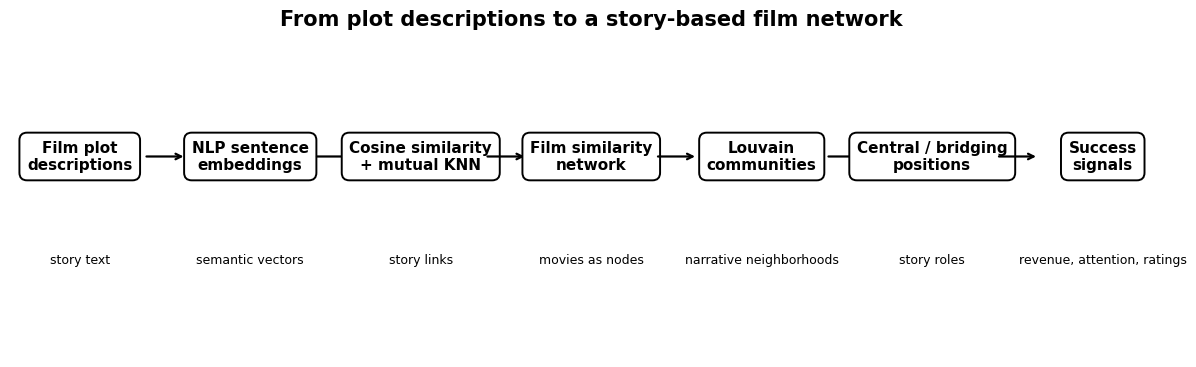

In [6]:
fig, ax = plt.subplots(figsize=(15, 4.2))
ax.axis("off")

steps = [
    ("Film plot\ndescriptions", "story text"),
    ("NLP sentence\nembeddings", "semantic vectors"),
    ("Cosine similarity\n+ mutual KNN", "story links"),
    ("Film similarity\nnetwork", "movies as nodes"),
    ("Louvain\ncommunities", "narrative neighborhoods"),
    ("Central / bridging\npositions", "story roles"),
    ("Success\nsignals", "revenue, attention, ratings")
]

x_positions = np.linspace(0.06, 0.94, len(steps))

for i, ((title, subtitle), x) in enumerate(zip(steps, x_positions)):
    ax.text(
        x, 0.62, title, ha="center", va="center", fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black", linewidth=1.4)
    )
    ax.text(x, 0.30, subtitle, ha="center", va="center", fontsize=9)
    if i < len(steps) - 1:
        ax.annotate(
            "", xy=(x_positions[i+1] - 0.055, 0.62), xytext=(x + 0.055, 0.62),
            arrowprops=dict(arrowstyle="->", lw=1.6)
        )

ax.set_title("From plot descriptions to a story-based film network", fontsize=15, fontweight="bold")
savefig("01_pipeline_diagram.png")
plt.show()

## Figure 02 — Corpus and analysis funnel

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/01_corpus_funnel_counts.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/02_corpus_funnel.png


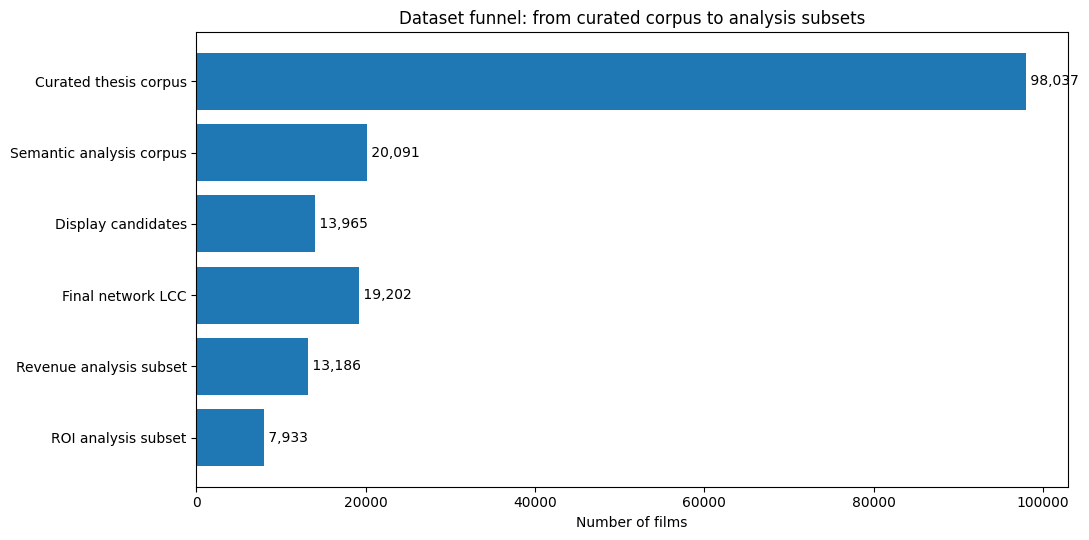

,stage,n_films
0,Curated thesis corpus,98037
1,Semantic analysis corpus,20091
2,Display candidates,13965
3,Final network LCC,19202
4,Revenue analysis subset,13186
5,ROI analysis subset,7933


In [7]:
funnel_rows = []

if "df_thesis" in optional_data:
    funnel_rows.append(("Curated thesis corpus", len(optional_data["df_thesis"])))
if "df_semantic" in optional_data:
    funnel_rows.append(("Semantic analysis corpus", len(optional_data["df_semantic"])))
if "df_display" in optional_data:
    funnel_rows.append(("Display candidates", len(optional_data["df_display"])))
if len(nodes) > 0:
    funnel_rows.append(("Final network LCC", len(nodes)))
if "df_revenue" in optional_data:
    funnel_rows.append(("Revenue analysis subset", len(optional_data["df_revenue"])))
if "df_roi" in optional_data:
    funnel_rows.append(("ROI analysis subset", len(optional_data["df_roi"])))

funnel = pd.DataFrame(funnel_rows, columns=["stage", "n_films"])
save_table(funnel, "01_corpus_funnel_counts.csv")

plt.figure(figsize=(11, 5.5))
plt.barh(funnel["stage"][::-1], funnel["n_films"][::-1])
plt.xlabel("Number of films")
plt.title("Dataset funnel: from curated corpus to analysis subsets")
for i, value in enumerate(funnel["n_films"][::-1]):
    plt.text(value, i, f" {value:,}", va="center", fontsize=10)
plt.tight_layout()
savefig("02_corpus_funnel.png")
plt.show()

display(funnel)

## Figure 03 — Network summary dashboard

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/03_network_summary_dashboard.png


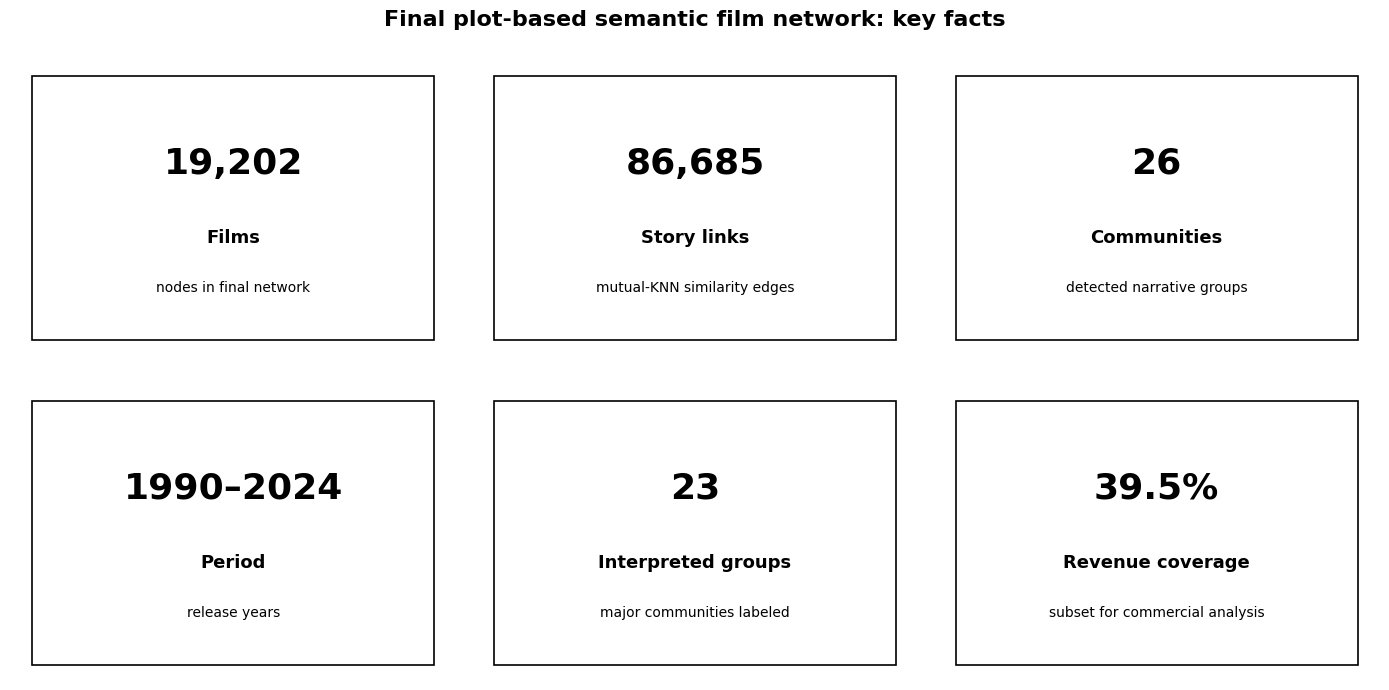

In [8]:
n_nodes = int(float(metric_lookup(network_basic, "n_nodes", len(nodes))))
n_edges = int(float(metric_lookup(network_basic, "n_edges", len(edges))))
n_communities = int(float(metric_lookup(network_basic, "n_communities", nodes["community_id"].nunique() if "community_id" in nodes.columns else np.nan)))
min_year = int(float(metric_lookup(network_basic, "min_year", nodes["release_year"].min() if "release_year" in nodes.columns else np.nan)))
max_year = int(float(metric_lookup(network_basic, "max_year", nodes["release_year"].max() if "release_year" in nodes.columns else np.nan)))
revenue_available_pct = float(metric_lookup(network_basic, "revenue_available_pct", modeling["revenue_clean"].notna().mean()*100 if "revenue_clean" in modeling.columns else np.nan))

cards = [
    ("Films", f"{n_nodes:,}", "nodes in final network"),
    ("Story links", f"{n_edges:,}", "mutual-KNN similarity edges"),
    ("Communities", f"{n_communities}", "detected narrative groups"),
    ("Period", f"{min_year}–{max_year}", "release years"),
    ("Interpreted groups", f"{len(community_labels)}", "major communities labeled"),
    ("Revenue coverage", f"{revenue_available_pct:.1f}%", "subset for commercial analysis")
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for ax, (title, value, subtitle) in zip(axes, cards):
    ax.axis("off")
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=26, fontweight="bold")
    ax.text(0.5, 0.38, title, ha="center", va="center", fontsize=13, fontweight="bold")
    ax.text(0.5, 0.22, subtitle, ha="center", va="center", fontsize=10)
    ax.add_patch(plt.Rectangle((0.05, 0.05), 0.9, 0.85, fill=False, linewidth=1.2, transform=ax.transAxes))

fig.suptitle("Final plot-based semantic film network: key facts", fontsize=16, fontweight="bold")
plt.tight_layout()
savefig("03_network_summary_dashboard.png")
plt.show()

# PART B — Network and narrative communities

These figures make the network visible and interpretable.


## Figure 04 — Sampled network map by narrative community

Detected edge columns: source_node_id target_node_id
Detected node id column: degree
Sample graph: 20 nodes, 0 edges
Plotted component: 1 nodes, 0 edges
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/04_network_map_community_sample.png


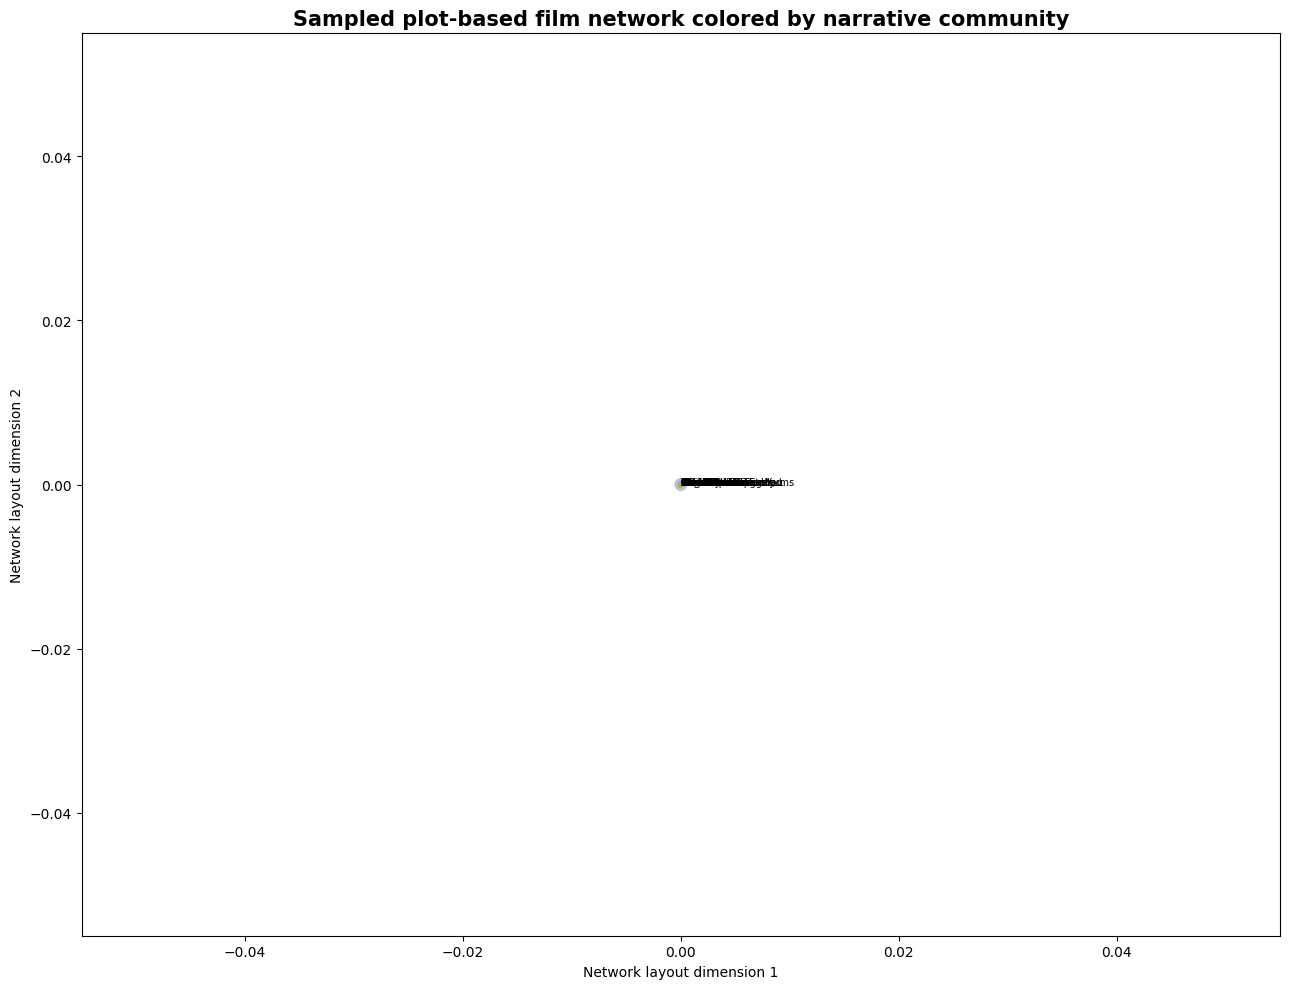

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/04_network_map_metadata.csv


In [9]:
# This creates a readable network map by sampling important/visible films.
# For very large graphs, the goal is not to plot every edge. The goal is to show community structure.

try:
    import networkx as nx

    source_col, target_col = detect_edge_columns(edges)
    node_id_col = detect_node_id_column(nodes, edges)

    print("Detected edge columns:", source_col, target_col)
    print("Detected node id column:", node_id_col)

    # Prepare node info
    node_info = nodes.copy()
    if "narrative_label" not in node_info.columns:
        node_info = node_info.merge(label_lookup, on="community_id", how="left")

    # Choose sample: top visible by vote_count + top central by weighted_degree + random within major communities
    sample_ids = set()

    if "vote_count" in node_info.columns:
        sample_ids.update(node_info.sort_values("vote_count", ascending=False).head(350)[node_id_col].dropna().tolist())

    if "weighted_degree" in node_info.columns:
        sample_ids.update(node_info.sort_values("weighted_degree", ascending=False).head(350)[node_id_col].dropna().tolist())

    # Add community-balanced sample
    if "community_id" in node_info.columns:
        for cid, group in node_info.groupby("community_id"):
            sample_n = min(30, len(group))
            sample_ids.update(group.sample(sample_n, random_state=42)[node_id_col].dropna().tolist())

    sample_ids = list(sample_ids)
    max_nodes = 900
    if len(sample_ids) > max_nodes:
        sample_ids = sample_ids[:max_nodes]

    sample_set = set(sample_ids)
    edge_sample = edges[
        edges[source_col].isin(sample_set) &
        edges[target_col].isin(sample_set)
    ].copy()

    # Limit edges for readability
    if len(edge_sample) > 3500:
        weight_cols = [c for c in edge_sample.columns if "weight" in c.lower() or "similarity" in c.lower() or "cosine" in c.lower()]
        if weight_cols:
            edge_sample = edge_sample.sort_values(weight_cols[0], ascending=False).head(3500)
        else:
            edge_sample = edge_sample.sample(3500, random_state=42)

    G = nx.Graph()
    for _, row in edge_sample.iterrows():
        G.add_edge(row[source_col], row[target_col])

    # Add isolated sampled nodes if needed
    G.add_nodes_from(sample_ids)

    print("Sample graph:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

    # Keep largest component of sample for better layout
    if G.number_of_nodes() > 0:
        largest_cc = max(nx.connected_components(G), key=len)
        G2 = G.subgraph(largest_cc).copy()
    else:
        G2 = G.copy()

    print("Plotted component:", G2.number_of_nodes(), "nodes,", G2.number_of_edges(), "edges")

    # Layout
    pos = nx.spring_layout(G2, seed=42, k=0.18, iterations=80)

    plot_nodes = node_info[node_info[node_id_col].isin(G2.nodes())].copy()
    plot_nodes["community_id"] = plot_nodes["community_id"].astype(int)

    # Convert positions
    xy = pd.DataFrame({
        node_id_col: list(pos.keys()),
        "x": [pos[n][0] for n in pos.keys()],
        "y": [pos[n][1] for n in pos.keys()]
    })
    plot_nodes = plot_nodes.merge(xy, on=node_id_col, how="inner")

    fig, ax = plt.subplots(figsize=(13, 10))

    # Draw edges faintly
    for u, v in G2.edges():
        if u in pos and v in pos:
            ax.plot(
                [pos[u][0], pos[v][0]],
                [pos[u][1], pos[v][1]],
                linewidth=0.25,
                alpha=0.12
            )

    scatter = ax.scatter(
        plot_nodes["x"],
        plot_nodes["y"],
        c=plot_nodes["community_id"],
        s=np.clip(plot_nodes.get("vote_count", pd.Series(20, index=plot_nodes.index)).fillna(20) / 200, 8, 90),
        alpha=0.85,
        cmap="tab20"
    )

    ax.set_title("Sampled plot-based film network colored by narrative community", fontsize=15, fontweight="bold")
    ax.set_xlabel("Network layout dimension 1")
    ax.set_ylabel("Network layout dimension 2")

    # Label top high vote-count nodes only
    label_df = plot_nodes.sort_values("vote_count", ascending=False).head(20) if "vote_count" in plot_nodes.columns else plot_nodes.head(20)
    for _, r in label_df.iterrows():
        ax.text(r["x"], r["y"], shorten(r.get("title", ""), 22), fontsize=7)

    plt.tight_layout()
    savefig("04_network_map_community_sample.png")
    plt.show()

    network_map_metadata = pd.DataFrame([{
        "node_id_column": node_id_col,
        "source_column": source_col,
        "target_column": target_col,
        "sample_nodes": G2.number_of_nodes(),
        "sample_edges": G2.number_of_edges()
    }])
    save_table(network_map_metadata, "04_network_map_metadata.csv")

except Exception as e:
    print("Network map failed:", e)
    print("This is not fatal. Continue with the rest of the visual gallery.")

## Figure 05 — Major narrative communities by size

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/05_major_communities_bar.png


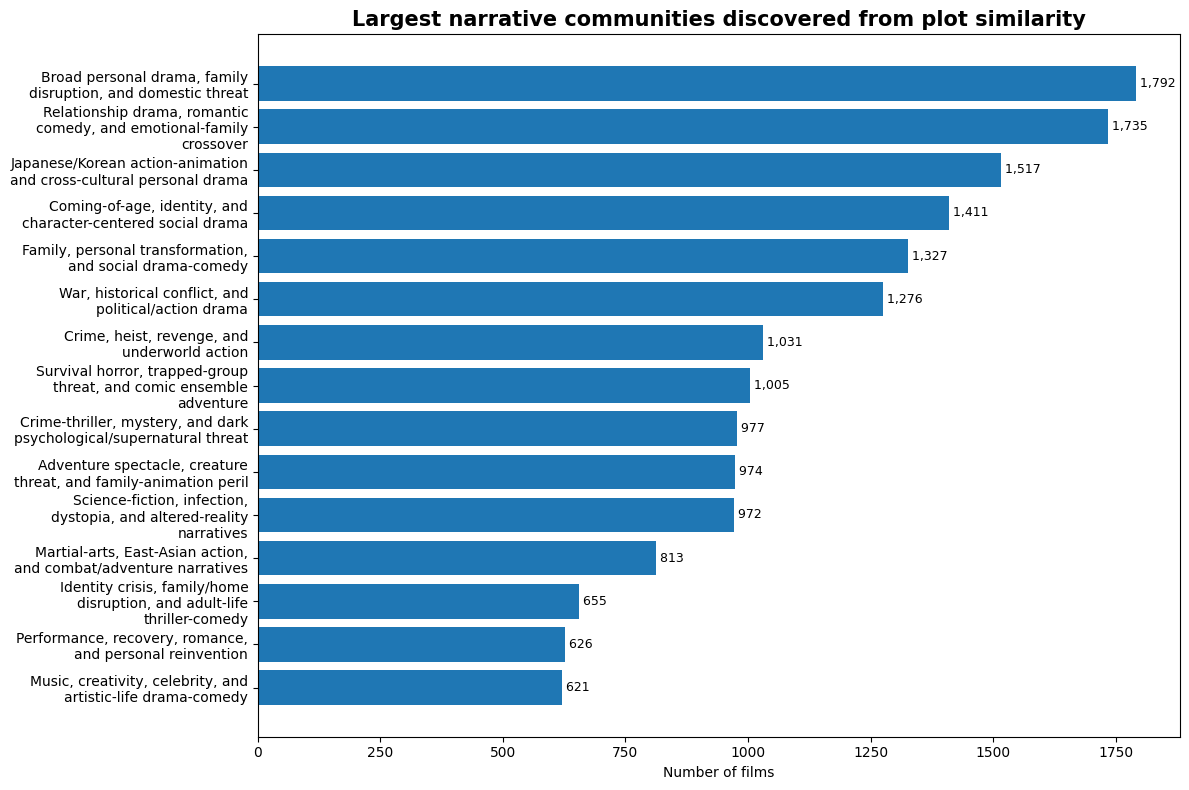

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/05_major_communities_for_plot.csv


PosixPath('/content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/05_major_communities_for_plot.csv')

In [10]:
comm = community_labels.copy()

label_col = "suggested_label_manual"
if label_col not in comm.columns:
    label_col = "narrative_label"

if "n_films" not in comm.columns:
    raise ValueError("community_labels needs n_films column.")

comm_top = comm.sort_values("n_films", ascending=False).head(15).copy()
comm_top["label_wrapped"] = comm_top[label_col].apply(lambda x: wrap_label(x, 34))

plt.figure(figsize=(12, 8))
plt.barh(comm_top["label_wrapped"][::-1], comm_top["n_films"][::-1])
plt.xlabel("Number of films")
plt.title("Largest narrative communities discovered from plot similarity", fontsize=15, fontweight="bold")
for i, value in enumerate(comm_top["n_films"][::-1]):
    plt.text(value, i, f" {value:,}", va="center", fontsize=9)
plt.tight_layout()
savefig("05_major_communities_bar.png")
plt.show()

save_table(comm_top, "05_major_communities_for_plot.csv")

## Figure 06 — Story community cards

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/06_story_community_cards.png


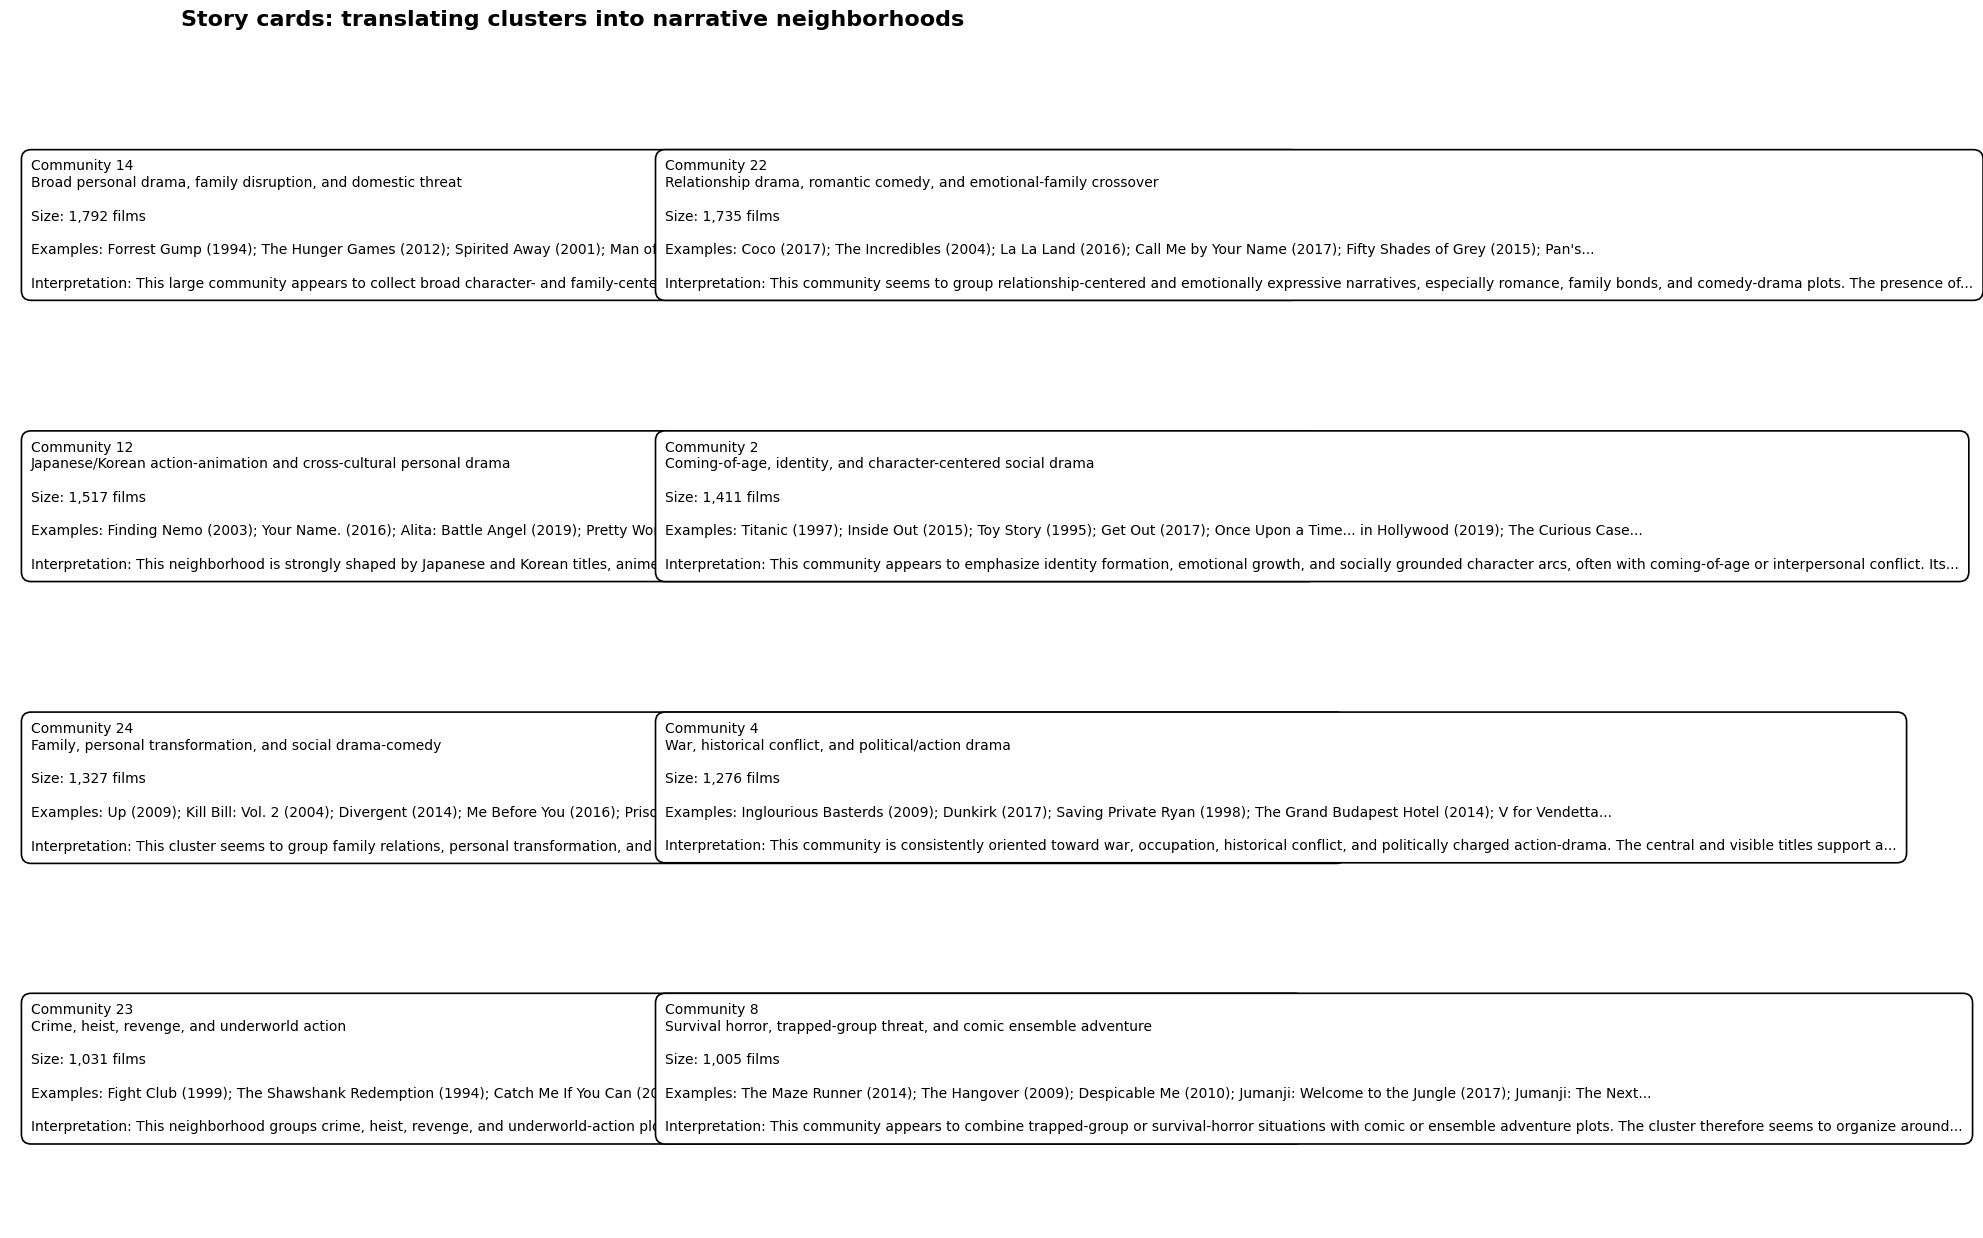

In [11]:
# Create a visual card board for the top 8 communities
top_cards = comm.sort_values("n_films", ascending=False).head(8).copy()

fig, axes = plt.subplots(4, 2, figsize=(15, 14))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_cards.iterrows()):
    ax.axis("off")

    cid = row.get("community_id", "")
    n = int(row.get("n_films", 0))
    label = str(row.get(label_col, "Narrative community"))

    examples = ""
    for possible in ["recognizable_examples", "visible_titles_vote_count", "central_titles_weighted_degree", "central_story_examples"]:
        if possible in row and pd.notna(row[possible]):
            examples = str(row[possible])
            break

    interpretation = ""
    for possible in ["interpretation_note_manual", "interpretation"]:
        if possible in row and pd.notna(row[possible]):
            interpretation = str(row[possible])
            break

    text = (
        f"Community {cid}\n"
        f"{label}\n\n"
        f"Size: {n:,} films\n\n"
        f"Examples: {shorten(examples, 130)}\n\n"
        f"Interpretation: {shorten(interpretation, 170)}"
    )

    ax.text(
        0.04, 0.96, text,
        ha="left", va="top",
        fontsize=10,
        linespacing=1.25,
        bbox=dict(boxstyle="round,pad=0.7", facecolor="white", edgecolor="black", linewidth=1.2)
    )

fig.suptitle("Story cards: translating clusters into narrative neighborhoods", fontsize=16, fontweight="bold")
plt.tight_layout()
savefig("06_story_community_cards.png")
plt.show()

## Figure 07 — Community genre-mix heatmap

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/07_community_genre_mix_heatmap.png


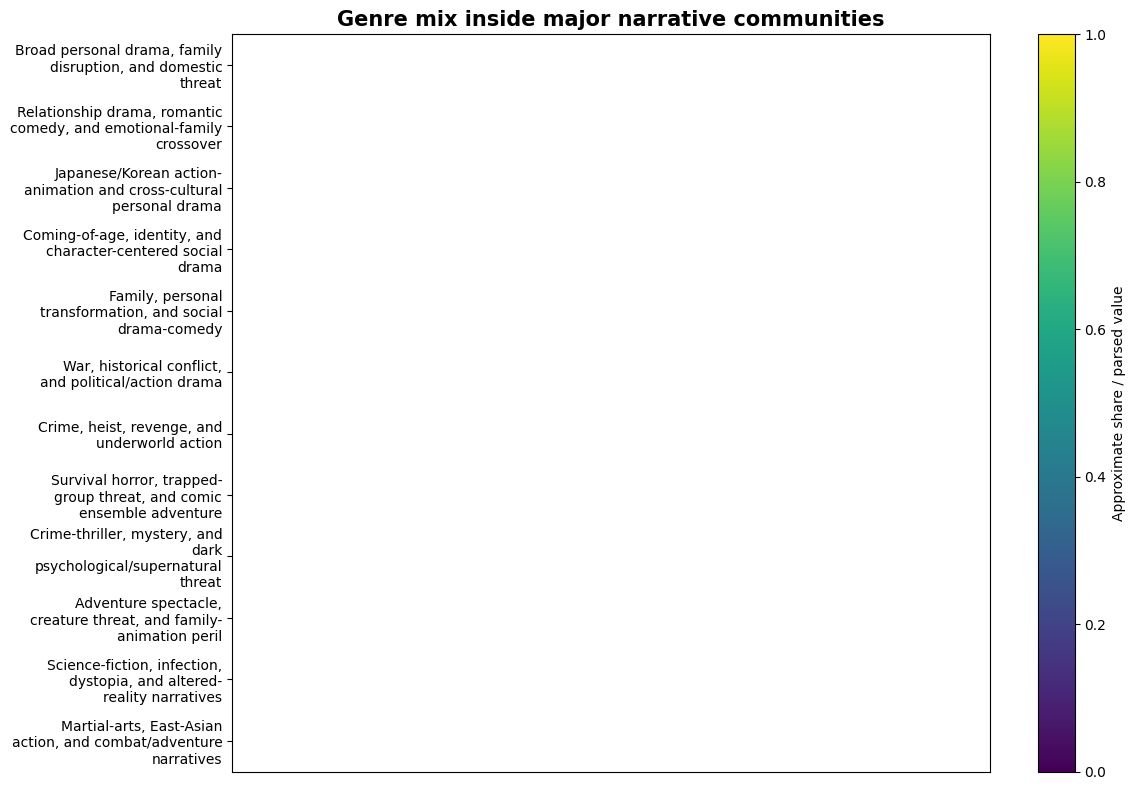

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/07_community_genre_mix_long.csv


In [12]:
# This parses the top_primary_genres column if available and makes a readable heatmap.
genre_col = None
for c in ["top_primary_genres", "top_genres"]:
    if c in comm.columns:
        genre_col = c
        break

if genre_col is not None:
    top_comm = comm.sort_values("n_films", ascending=False).head(12).copy()

    rows = []
    for _, row in top_comm.iterrows():
        cid = row["community_id"]
        label = row[label_col]
        s = str(row[genre_col])
        # Extract patterns like "Drama: 35%" or "Drama (35%)"; fallback split commas
        parts = re.split(r",|;", s)
        for part in parts:
            part = part.strip()
            if not part:
                continue

            genre = re.sub(r"[:(].*", "", part).strip()
            pct_match = re.search(r"([0-9]+\\.?[0-9]*)\\s*%?", part)
            pct = float(pct_match.group(1)) if pct_match else np.nan

            if genre:
                rows.append({
                    "community_id": cid,
                    "community_label": label,
                    "genre": genre,
                    "value": pct
                })

    genre_long = pd.DataFrame(rows)

    if not genre_long.empty:
        # Keep top genres
        top_genres = genre_long["genre"].value_counts().head(10).index.tolist()
        genre_long = genre_long[genre_long["genre"].isin(top_genres)]

        mat = genre_long.pivot_table(
            index="community_label",
            columns="genre",
            values="value",
            aggfunc="max",
            fill_value=0
        )

        # Keep same community size order
        ordered_labels = top_comm[label_col].tolist()
        mat = mat.reindex(ordered_labels)
        mat.index = [wrap_label(x, 28) for x in mat.index]

        plt.figure(figsize=(12, 8))
        plt.imshow(mat.values, aspect="auto")
        plt.xticks(range(mat.shape[1]), mat.columns, rotation=45, ha="right")
        plt.yticks(range(mat.shape[0]), mat.index)
        plt.colorbar(label="Approximate share / parsed value")
        plt.title("Genre mix inside major narrative communities", fontsize=15, fontweight="bold")
        plt.tight_layout()
        savefig("07_community_genre_mix_heatmap.png")
        plt.show()

        save_table(genre_long, "07_community_genre_mix_long.csv")
    else:
        print("Could not parse genre mix.")
else:
    print("No top_primary_genres/top_genres column found.")

# PART C — Story roles: central and bridging films

These figures are more important than raw centrality CSVs.


## Figure 08 — Central vs bridging scatter

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/08_central_vs_bridging_scatter.png


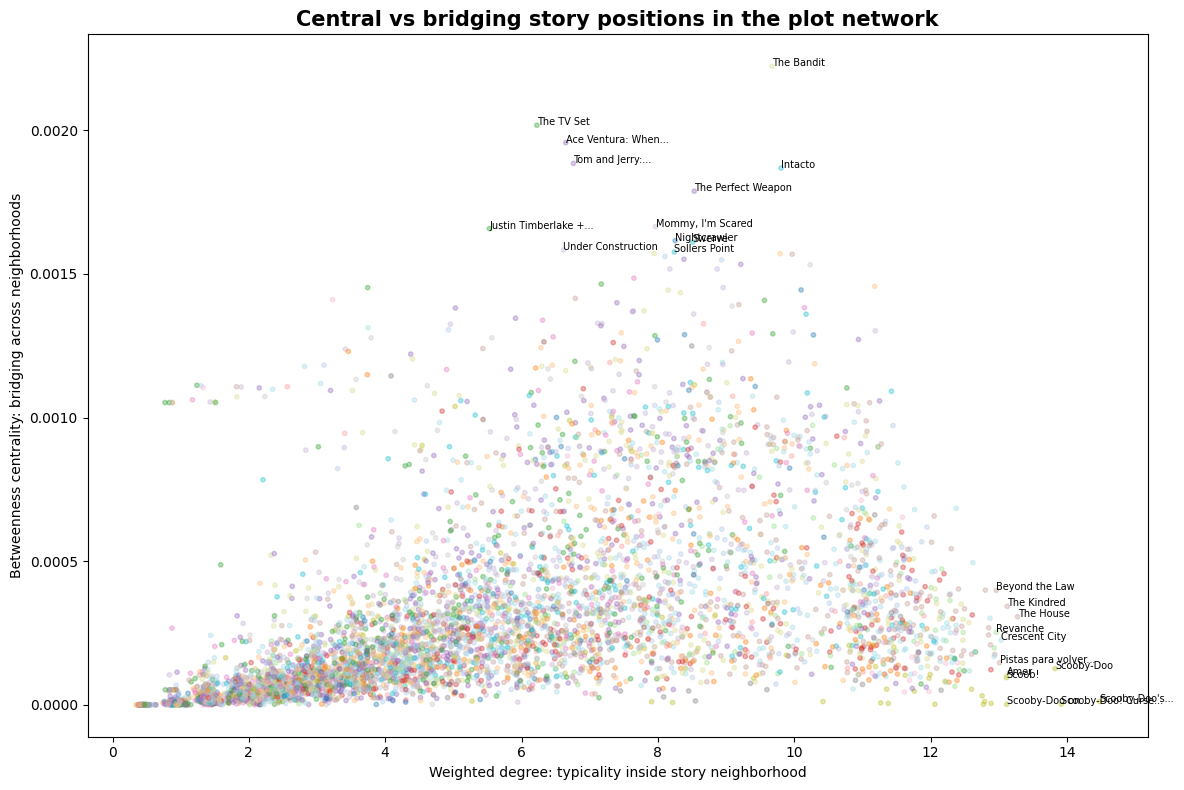

In [13]:
plot_df = modeling.copy()

needed = ["weighted_degree", "betweenness_centrality_sampled", "community_id"]
missing = [c for c in needed if c not in plot_df.columns]

if not missing:
    # Sampling for readability
    sample = plot_df.dropna(subset=["weighted_degree", "betweenness_centrality_sampled"]).copy()
    if len(sample) > 6000:
        # keep important points plus random background
        important = sample.sort_values("betweenness_centrality_sampled", ascending=False).head(500)
        important2 = sample.sort_values("weighted_degree", ascending=False).head(500)
        random_bg = sample.sample(5000, random_state=42)
        sample = pd.concat([important, important2, random_bg]).drop_duplicates()

    plt.figure(figsize=(12, 8))
    plt.scatter(
        sample["weighted_degree"],
        sample["betweenness_centrality_sampled"],
        c=sample["community_id"],
        s=10,
        alpha=0.35,
        cmap="tab20"
    )

    # Label selected bridges and central examples
    label_candidates = pd.concat([
        sample.sort_values("betweenness_centrality_sampled", ascending=False).head(12),
        sample.sort_values("weighted_degree", ascending=False).head(12)
    ]).drop_duplicates()

    for _, r in label_candidates.iterrows():
        plt.text(
            r["weighted_degree"],
            r["betweenness_centrality_sampled"],
            shorten(r.get("title", ""), 22),
            fontsize=7
        )

    plt.xlabel("Weighted degree: typicality inside story neighborhood")
    plt.ylabel("Betweenness centrality: bridging across neighborhoods")
    plt.title("Central vs bridging story positions in the plot network", fontsize=15, fontweight="bold")
    plt.tight_layout()
    savefig("08_central_vs_bridging_scatter.png")
    plt.show()
else:
    print("Missing columns:", missing)

## Figure 09 — Central films examples board

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/09_central_films_examples_board.png


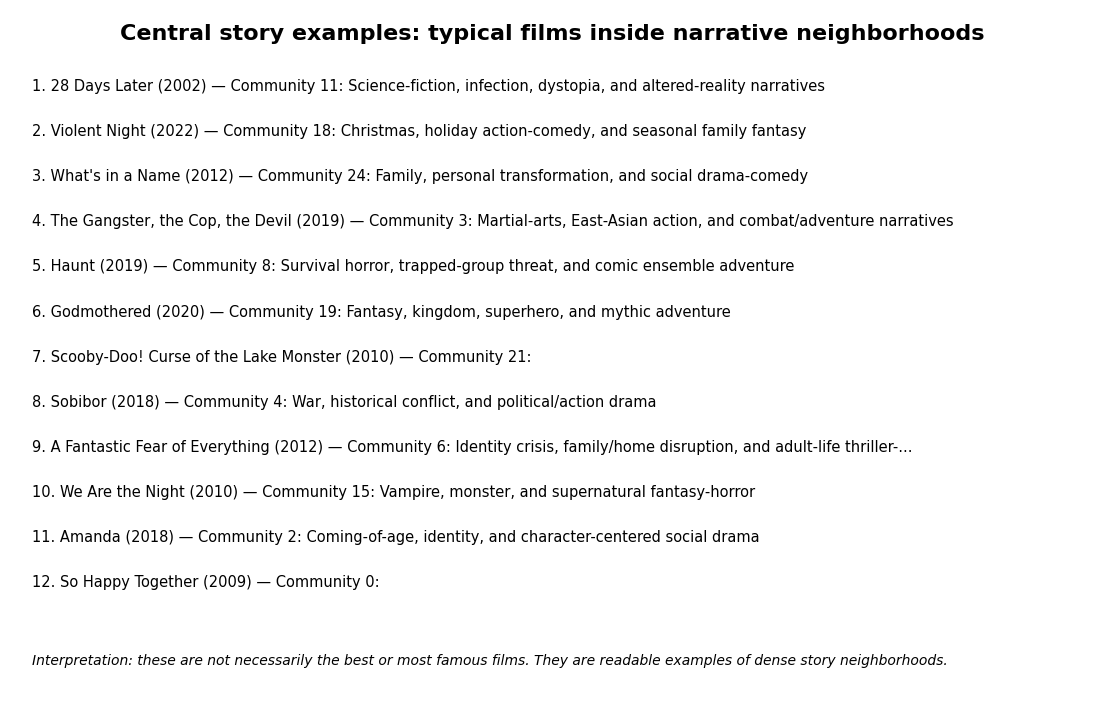

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/09_central_films_examples_board_data.csv


PosixPath('/content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/09_central_films_examples_board_data.csv')

In [14]:
central_board = central_examples.copy()
if "narrative_label" not in central_board.columns:
    central_board = central_board.merge(label_lookup, on="community_id", how="left")

# Pick top 12 by visible ranking, or weighted degree
rank_col = "rank_within_community" if "rank_within_community" in central_board.columns else None
if rank_col:
    central_main = central_board[central_board[rank_col] == 1].copy()
else:
    central_main = central_board.sort_values("weighted_degree", ascending=False).groupby("community_id").head(1)

if "vote_count" in central_main.columns:
    central_main = central_main.sort_values("vote_count", ascending=False).head(12)
else:
    central_main = central_main.head(12)

fig, ax = plt.subplots(figsize=(14, 9))
ax.axis("off")

title = "Central story examples: typical films inside narrative neighborhoods"
ax.text(0.5, 0.98, title, ha="center", va="top", fontsize=16, fontweight="bold")

y = 0.90
for i, (_, row) in enumerate(central_main.iterrows(), start=1):
    line = (
        f"{i}. {clean_title(row.get('title', ''))} ({int(row.get('release_year')) if pd.notna(row.get('release_year')) else '—'})"
        f" — Community {row.get('community_id')}: {shorten(row.get('narrative_label', ''), 70)}"
    )
    ax.text(0.02, y, line, ha="left", va="top", fontsize=10.5)
    y -= 0.065

ax.text(
    0.02, 0.05,
    "Interpretation: these are not necessarily the best or most famous films. They are readable examples of dense story neighborhoods.",
    ha="left", va="bottom", fontsize=10, style="italic"
)

savefig("09_central_films_examples_board.png")
plt.show()

save_table(central_main, "09_central_films_examples_board_data.csv")

## Figure 10 — Bridging films examples board

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/10_bridging_films_examples_board.png


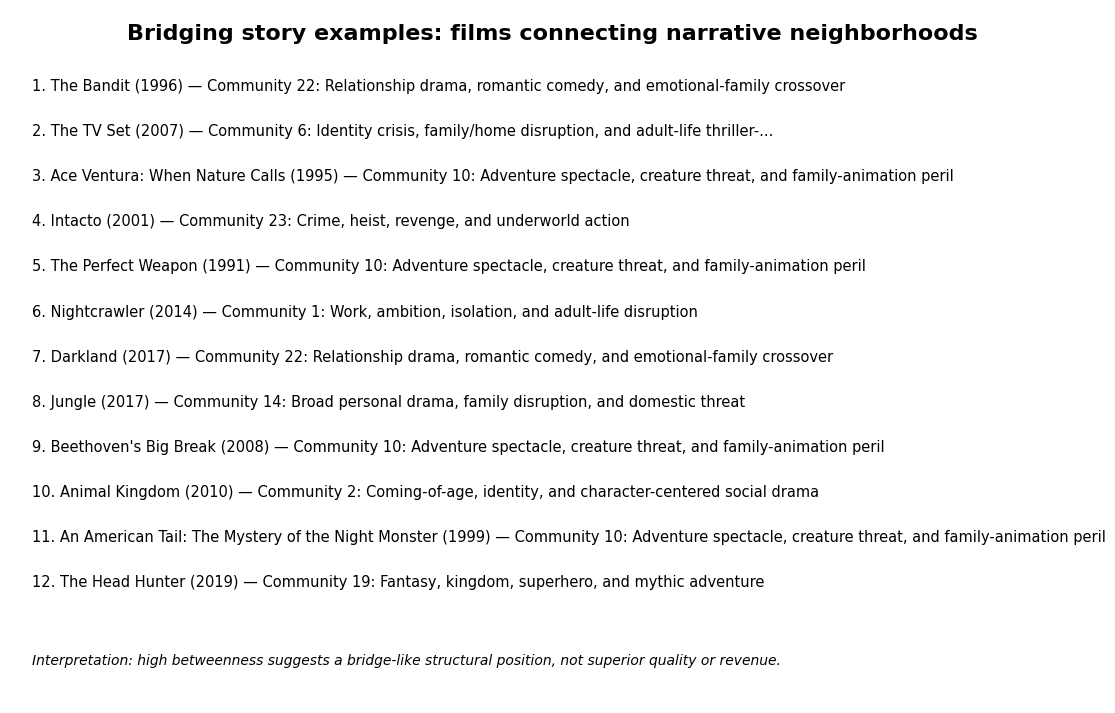

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/10_bridging_films_examples_board_data.csv


PosixPath('/content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/10_bridging_films_examples_board_data.csv')

In [15]:
bridge_board = bridging_examples.copy()
if "narrative_label" not in bridge_board.columns:
    bridge_board = bridge_board.merge(label_lookup, on="community_id", how="left")

bridge_main = bridge_board.head(12).copy()

fig, ax = plt.subplots(figsize=(14, 9))
ax.axis("off")

title = "Bridging story examples: films connecting narrative neighborhoods"
ax.text(0.5, 0.98, title, ha="center", va="top", fontsize=16, fontweight="bold")

y = 0.90
for i, (_, row) in enumerate(bridge_main.iterrows(), start=1):
    line = (
        f"{i}. {clean_title(row.get('title', ''))} ({int(row.get('release_year')) if pd.notna(row.get('release_year')) else '—'})"
        f" — Community {row.get('community_id')}: {shorten(row.get('narrative_label', ''), 70)}"
    )
    ax.text(0.02, y, line, ha="left", va="top", fontsize=10.5)
    y -= 0.065

ax.text(
    0.02, 0.05,
    "Interpretation: high betweenness suggests a bridge-like structural position, not superior quality or revenue.",
    ha="left", va="bottom", fontsize=10, style="italic"
)

savefig("10_bridging_films_examples_board.png")
plt.show()

save_table(bridge_main, "10_bridging_films_examples_board_data.csv")

# PART D — Success as multidimensional

These figures protect the thesis from becoming a pure box-office analysis.


## Figure 11 — Success dimensions diagram

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/11_success_dimensions_diagram.png


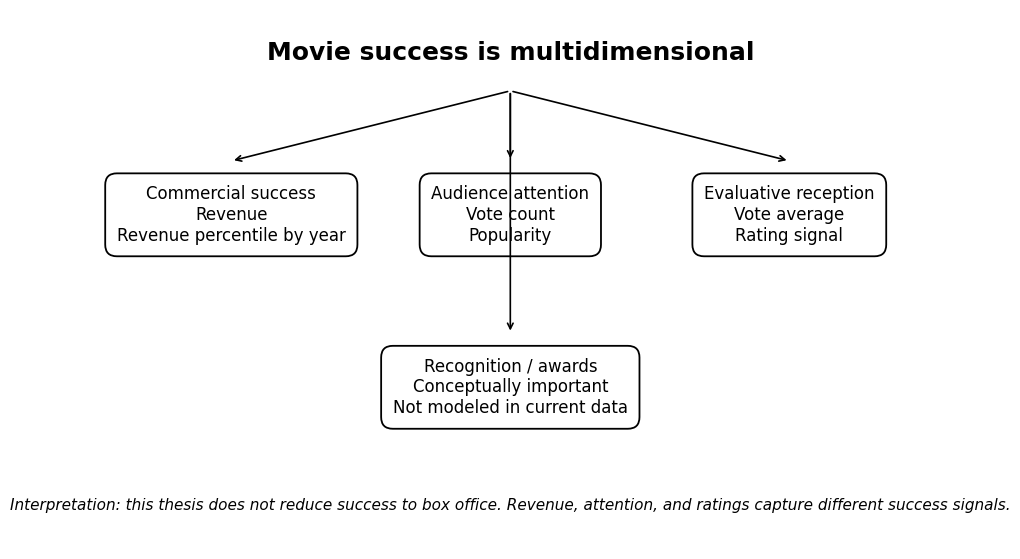

In [20]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.axis("off")

ax.text(0.5, 0.92, "Movie success is multidimensional", ha="center", va="center", fontsize=18, fontweight="bold")

boxes = [
    (0.20, 0.62, "Commercial success\nRevenue\nRevenue percentile by year"),
    (0.50, 0.62, "Audience attention\nVote count\nPopularity"),
    (0.80, 0.62, "Evaluative reception\nVote average\nRating signal"),
    (0.50, 0.30, "Recognition / awards\nConceptually important\nNot modeled in current data")
]

for x, y, text in boxes:
    ax.text(
        x, y, text,
        ha="center", va="center",
        fontsize=12,
        bbox=dict(boxstyle="round,pad=0.7", facecolor="white", edgecolor="black", linewidth=1.3)
    )
    ax.annotate("", xy=(x, y + 0.10), xytext=(0.5, 0.85), arrowprops=dict(arrowstyle="->", lw=1.2))

ax.text(
    0.5, 0.08,
    "Interpretation: this thesis does not reduce success to box office. Revenue, attention, and ratings capture different success signals.",
    ha="center", va="center", fontsize=11, style="italic"
)

savefig("11_success_dimensions_diagram.png")
plt.show()

## Figure 12 — Hidden/evaluative success quadrant

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/12_hidden_evaluative_success_quadrant.png


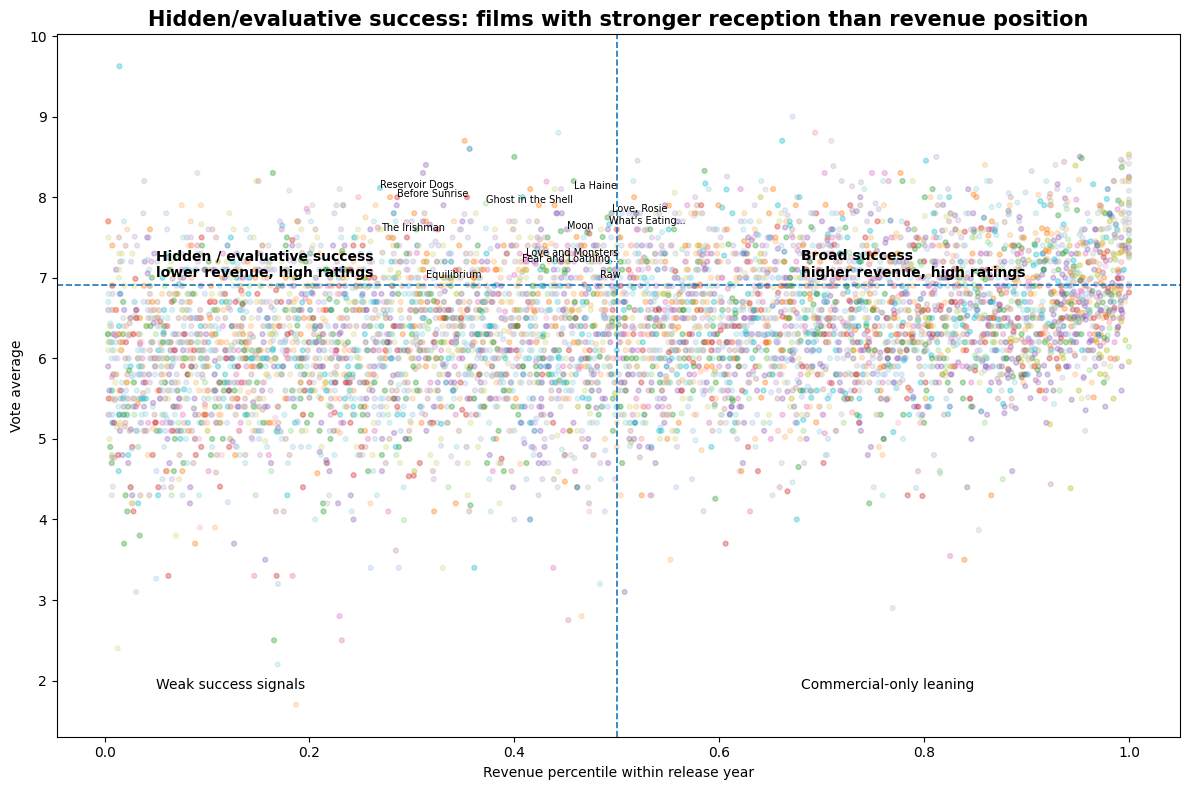

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/12_hidden_evaluative_success_candidates.csv
Hidden/evaluative success candidates: (687, 62)


In [21]:
quad = modeling.copy()

# Need revenue percentile and vote average
if "revenue_percentile_year" in quad.columns and "vote_average" in quad.columns:
    quad = quad.dropna(subset=["revenue_percentile_year", "vote_average"]).copy()

    # Sample background
    bg = quad.sample(min(len(quad), 6000), random_state=42)

    vote_threshold = quad["vote_average"].quantile(0.75)
    revenue_threshold = 0.50

    hidden = quad[
        (quad["revenue_percentile_year"] <= revenue_threshold) &
        (quad["vote_average"] >= vote_threshold)
    ].copy()

    # Prioritize visible/fan-signal examples
    sort_cols = [c for c in ["vote_count", "popularity"] if c in hidden.columns]
    if sort_cols:
        hidden = hidden.sort_values(sort_cols, ascending=False)

    hidden_top = hidden.head(20)

    plt.figure(figsize=(12, 8))
    plt.scatter(
        bg["revenue_percentile_year"],
        bg["vote_average"],
        c=bg["community_id"],
        s=12,
        alpha=0.35,
        cmap="tab20"
    )
    plt.axvline(revenue_threshold, linestyle="--", linewidth=1.2)
    plt.axhline(vote_threshold, linestyle="--", linewidth=1.2)

    plt.text(0.05, vote_threshold + 0.1, "Hidden / evaluative success\nlower revenue, high ratings", fontsize=10, fontweight="bold")
    plt.text(0.68, vote_threshold + 0.1, "Broad success\nhigher revenue, high ratings", fontsize=10, fontweight="bold")
    plt.text(0.05, quad["vote_average"].min() + 0.2, "Weak success signals", fontsize=10)
    plt.text(0.68, quad["vote_average"].min() + 0.2, "Commercial-only leaning", fontsize=10)

    for _, r in hidden_top.head(12).iterrows():
        plt.text(
            r["revenue_percentile_year"],
            r["vote_average"],
            shorten(r.get("title", ""), 22),
            fontsize=7
        )

    plt.xlabel("Revenue percentile within release year")
    plt.ylabel("Vote average")
    plt.title("Hidden/evaluative success: films with stronger reception than revenue position", fontsize=15, fontweight="bold")
    plt.tight_layout()
    savefig("12_hidden_evaluative_success_quadrant.png")
    plt.show()

    save_table(hidden_top, "12_hidden_evaluative_success_candidates.csv")
    print("Hidden/evaluative success candidates:", hidden.shape)
else:
    print("Missing revenue_percentile_year or vote_average.")

## Figure 13 — Fan-attention success quadrant

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/13_fan_attention_success_quadrant.png


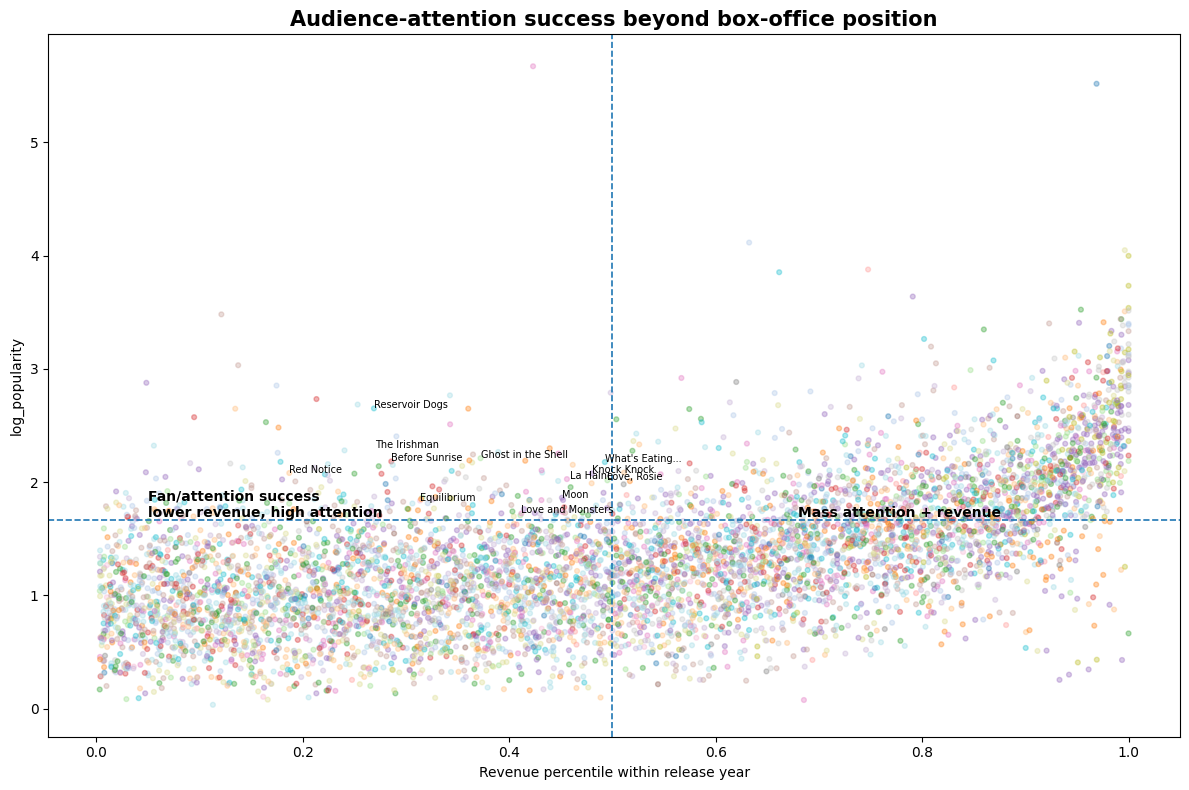

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/13_fan_attention_success_candidates.csv
Fan/attention success candidates: (281, 63)


In [22]:
fan = modeling.copy()

attention_col = None
for c in ["log_popularity", "popularity", "vote_count"]:
    if c in fan.columns:
        attention_col = c
        break

if "revenue_percentile_year" in fan.columns and attention_col is not None:
    fan = fan.dropna(subset=["revenue_percentile_year", attention_col]).copy()

    # Transform vote_count/popularity if needed
    if attention_col in ["popularity", "vote_count"]:
        fan["attention_signal"] = np.log1p(fan[attention_col].clip(lower=0))
        attention_label = f"log(1 + {attention_col})"
    else:
        fan["attention_signal"] = fan[attention_col]
        attention_label = attention_col

    bg = fan.sample(min(len(fan), 6000), random_state=42)

    attention_threshold = fan["attention_signal"].quantile(0.75)
    revenue_threshold = 0.50

    fan_hidden = fan[
        (fan["revenue_percentile_year"] <= revenue_threshold) &
        (fan["attention_signal"] >= attention_threshold)
    ].copy()

    if "vote_count" in fan_hidden.columns:
        fan_hidden = fan_hidden.sort_values("vote_count", ascending=False)
    else:
        fan_hidden = fan_hidden.sort_values("attention_signal", ascending=False)

    fan_hidden_top = fan_hidden.head(20)

    plt.figure(figsize=(12, 8))
    plt.scatter(
        bg["revenue_percentile_year"],
        bg["attention_signal"],
        c=bg["community_id"],
        s=12,
        alpha=0.35,
        cmap="tab20"
    )
    plt.axvline(revenue_threshold, linestyle="--", linewidth=1.2)
    plt.axhline(attention_threshold, linestyle="--", linewidth=1.2)

    plt.text(0.05, attention_threshold + 0.03, "Fan/attention success\nlower revenue, high attention", fontsize=10, fontweight="bold")
    plt.text(0.68, attention_threshold + 0.03, "Mass attention + revenue", fontsize=10, fontweight="bold")

    for _, r in fan_hidden_top.head(12).iterrows():
        plt.text(
            r["revenue_percentile_year"],
            r["attention_signal"],
            shorten(r.get("title", ""), 22),
            fontsize=7
        )

    plt.xlabel("Revenue percentile within release year")
    plt.ylabel(attention_label)
    plt.title("Audience-attention success beyond box-office position", fontsize=15, fontweight="bold")
    plt.tight_layout()
    savefig("13_fan_attention_success_quadrant.png")
    plt.show()

    save_table(fan_hidden_top, "13_fan_attention_success_candidates.csv")
    print("Fan/attention success candidates:", fan_hidden.shape)
else:
    print("Missing revenue_percentile_year or attention variable.")

## Figure 14 — Community success heatmap

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/14_community_success_heatmap.png


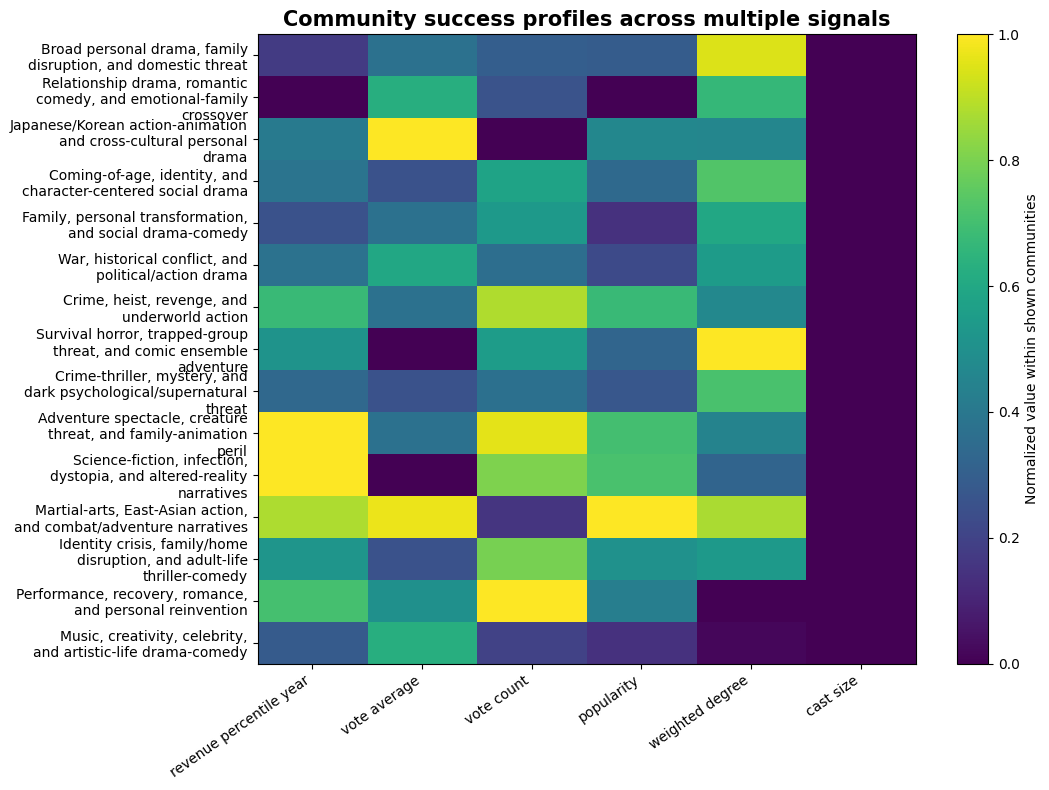

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/14_community_success_heatmap_data.csv


In [23]:
if community_success is not None and not community_success.empty:
    cs = community_success.copy()

    if "narrative_label" not in cs.columns:
        cs = cs.merge(label_lookup, on="community_id", how="left")

    # Use largest 15 communities
    cs = cs.sort_values("n_films", ascending=False).head(15).copy()

    metrics = [
        "median_revenue_percentile_year",
        "median_vote_average",
        "median_vote_count",
        "median_popularity",
        "median_weighted_degree",
        "median_cast_size"
    ]
    metrics = [m for m in metrics if m in cs.columns]

    if len(metrics) >= 2:
        mat = cs[metrics].copy()

        # Normalize columns for visual comparison
        mat_norm = mat.copy()
        for col in metrics:
            x = mat_norm[col].astype(float)
            if x.max() != x.min():
                mat_norm[col] = (x - x.min()) / (x.max() - x.min())
            else:
                mat_norm[col] = 0

        labels = cs["narrative_label"].apply(lambda x: wrap_label(x, 32)).tolist()

        plt.figure(figsize=(11, 8))
        plt.imshow(mat_norm.values, aspect="auto")
        plt.xticks(range(len(metrics)), [m.replace("median_", "").replace("_", " ") for m in metrics], rotation=35, ha="right")
        plt.yticks(range(len(labels)), labels)
        plt.colorbar(label="Normalized value within shown communities")
        plt.title("Community success profiles across multiple signals", fontsize=15, fontweight="bold")
        plt.tight_layout()
        savefig("14_community_success_heatmap.png")
        plt.show()

        save_table(cs, "14_community_success_heatmap_data.csv")
    else:
        print("Not enough success metrics available.")
else:
    print("Community success table not available.")

# PART E — Models as simple visuals, not walls of coefficients


## Figure 15 — Model fit by success dimension

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/15_model_fit_by_success_dimension.png


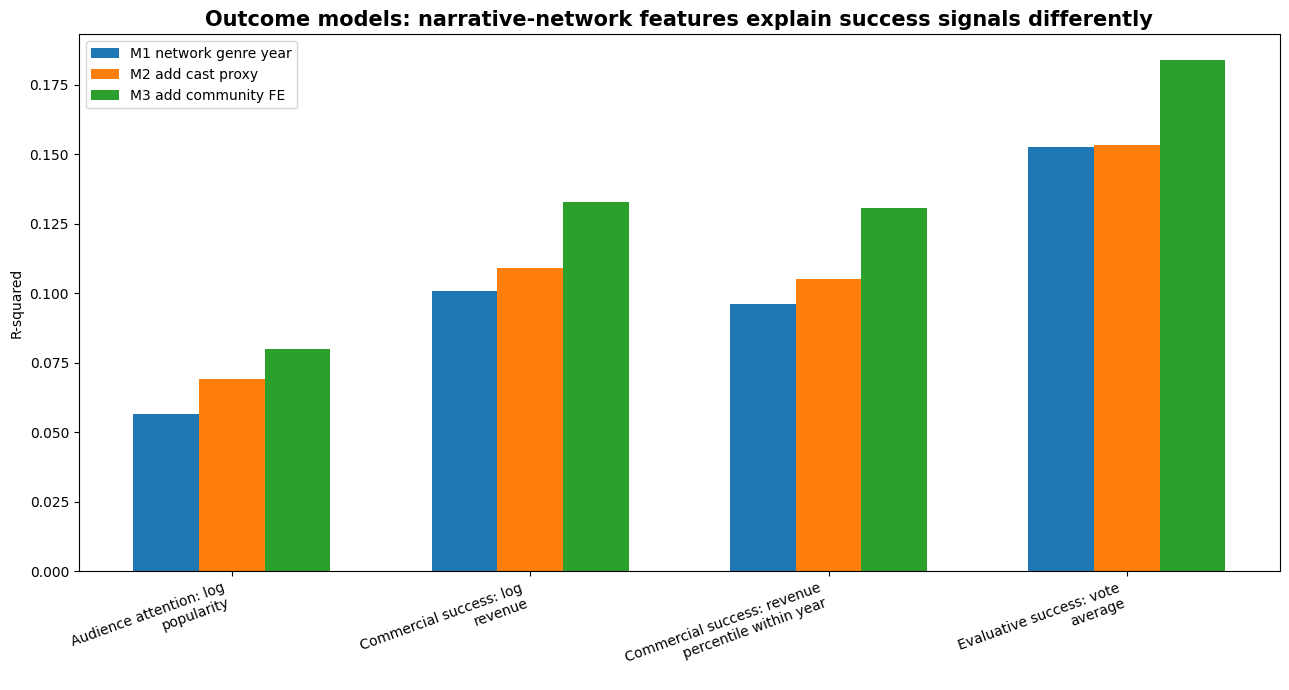

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/15_model_fit_plot_data.csv


In [24]:
if model_summary is not None and not model_summary.empty:
    ms = model_summary.copy()

    # Expected columns from Notebook 6 final_model_summary_table
    outcome_col = "outcome_label" if "outcome_label" in ms.columns else ms.columns[0]

    r2_cols = [
        "M1_network_genre_year",
        "M2_add_cast_proxy",
        "M3_add_community_FE"
    ]
    r2_cols = [c for c in r2_cols if c in ms.columns]

    plot = ms[[outcome_col] + r2_cols].copy()
    labels = plot[outcome_col].apply(lambda x: wrap_label(x, 28)).tolist()

    x = np.arange(len(plot))
    width = 0.22

    plt.figure(figsize=(13, 7))

    for i, col in enumerate(r2_cols):
        plt.bar(x + (i - 1) * width, plot[col], width=width, label=col.replace("_", " "))

    plt.xticks(x, labels, rotation=20, ha="right")
    plt.ylabel("R-squared")
    plt.title("Outcome models: narrative-network features explain success signals differently", fontsize=15, fontweight="bold")
    plt.legend()
    plt.tight_layout()
    savefig("15_model_fit_by_success_dimension.png")
    plt.show()

    save_table(plot, "15_model_fit_plot_data.csv")
else:
    print("Model summary not available.")

## Figure 16 — Model improvement from cast proxies and community effects

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/16_model_improvement_gains.png


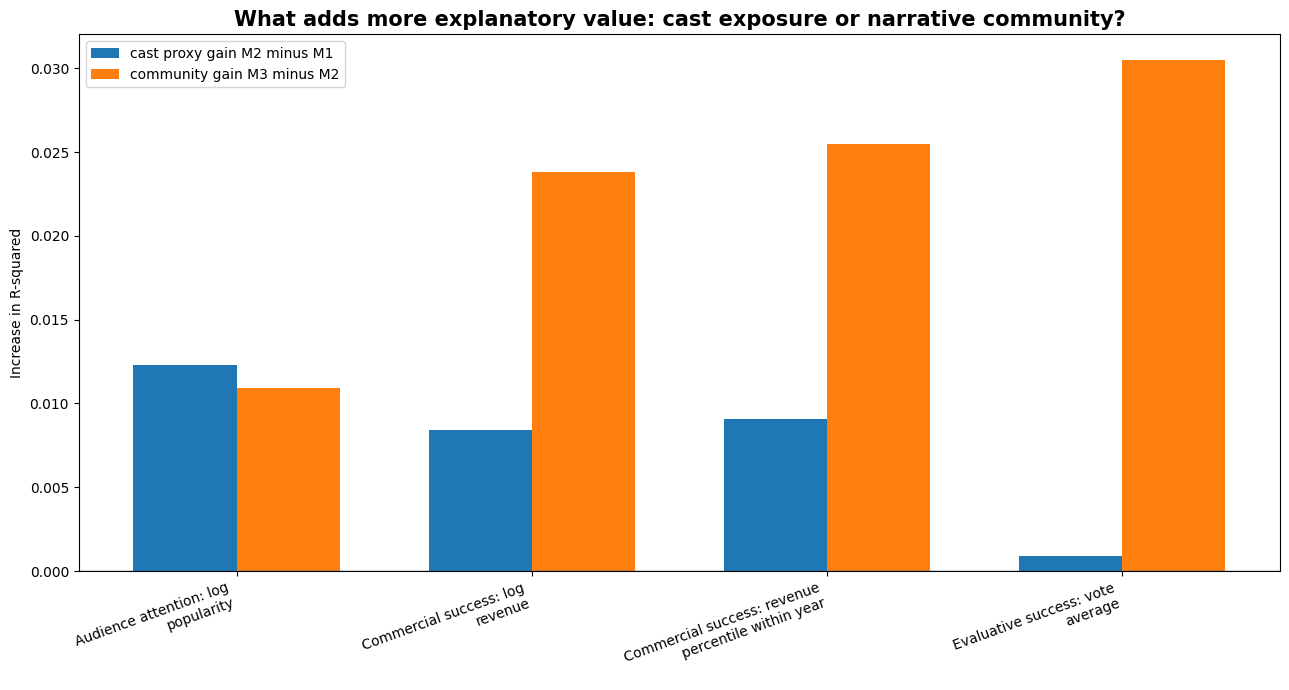

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/16_model_improvement_gains_data.csv


In [25]:
if model_summary is not None and not model_summary.empty:
    ms = model_summary.copy()
    outcome_col = "outcome_label" if "outcome_label" in ms.columns else ms.columns[0]

    gain_cols = [
        "cast_proxy_gain_M2_minus_M1",
        "community_gain_M3_minus_M2"
    ]
    gain_cols = [c for c in gain_cols if c in ms.columns]

    if gain_cols:
        plot = ms[[outcome_col] + gain_cols].copy()
        labels = plot[outcome_col].apply(lambda x: wrap_label(x, 28)).tolist()
        x = np.arange(len(plot))
        width = 0.35

        plt.figure(figsize=(13, 7))
        for i, col in enumerate(gain_cols):
            plt.bar(x + (i - 0.5) * width, plot[col], width=width, label=col.replace("_", " "))

        plt.axhline(0, linewidth=1)
        plt.xticks(x, labels, rotation=20, ha="right")
        plt.ylabel("Increase in R-squared")
        plt.title("What adds more explanatory value: cast exposure or narrative community?", fontsize=15, fontweight="bold")
        plt.legend()
        plt.tight_layout()
        savefig("16_model_improvement_gains.png")
        plt.show()

        save_table(plot, "16_model_improvement_gains_data.csv")
    else:
        print("Gain columns not found.")
else:
    print("Model summary not available.")

# PART F — Community-level visual profiles


## Figure 17 — Community size vs evaluative reception

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/17_community_size_vs_vote_average.png


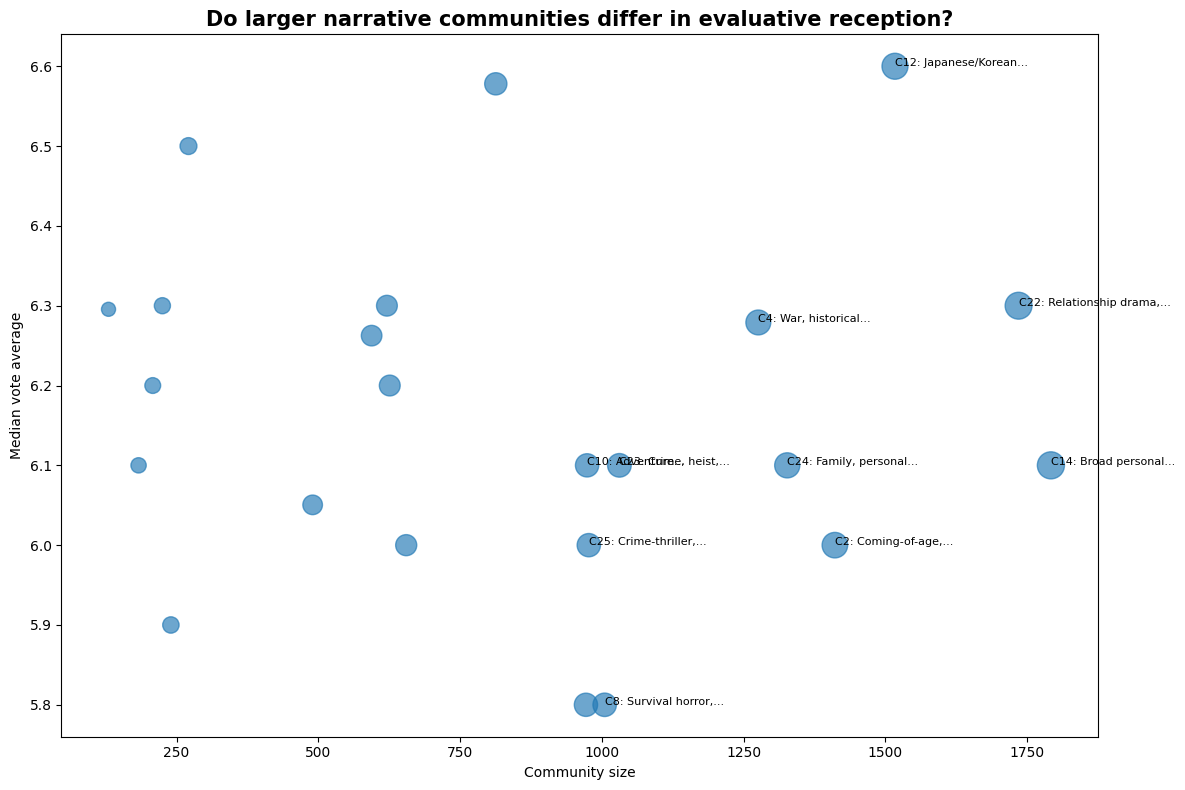

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/17_community_size_vs_vote_average_data.csv


In [26]:
if community_success is not None and not community_success.empty:
    cs = community_success.copy()
    if "narrative_label" not in cs.columns:
        cs = cs.merge(label_lookup, on="community_id", how="left")

    if all(c in cs.columns for c in ["n_films", "median_vote_average"]):
        cs_plot = cs.dropna(subset=["n_films", "median_vote_average"]).copy()
        cs_plot = cs_plot.sort_values("n_films", ascending=False).head(23)

        size_vals = np.sqrt(cs_plot["n_films"]) * 9

        plt.figure(figsize=(12, 8))
        plt.scatter(
            cs_plot["n_films"],
            cs_plot["median_vote_average"],
            s=size_vals,
            alpha=0.65
        )

        for _, r in cs_plot.sort_values("n_films", ascending=False).head(10).iterrows():
            plt.text(
                r["n_films"],
                r["median_vote_average"],
                f"C{int(r['community_id'])}: {shorten(r['narrative_label'], 22)}",
                fontsize=8
            )

        plt.xlabel("Community size")
        plt.ylabel("Median vote average")
        plt.title("Do larger narrative communities differ in evaluative reception?", fontsize=15, fontweight="bold")
        plt.tight_layout()
        savefig("17_community_size_vs_vote_average.png")
        plt.show()

        save_table(cs_plot, "17_community_size_vs_vote_average_data.csv")
    else:
        print("Required columns not available.")
else:
    print("Community success not available.")

## Figure 18 — Community revenue vs rating profile

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/figures/18_community_revenue_vs_rating_profile.png


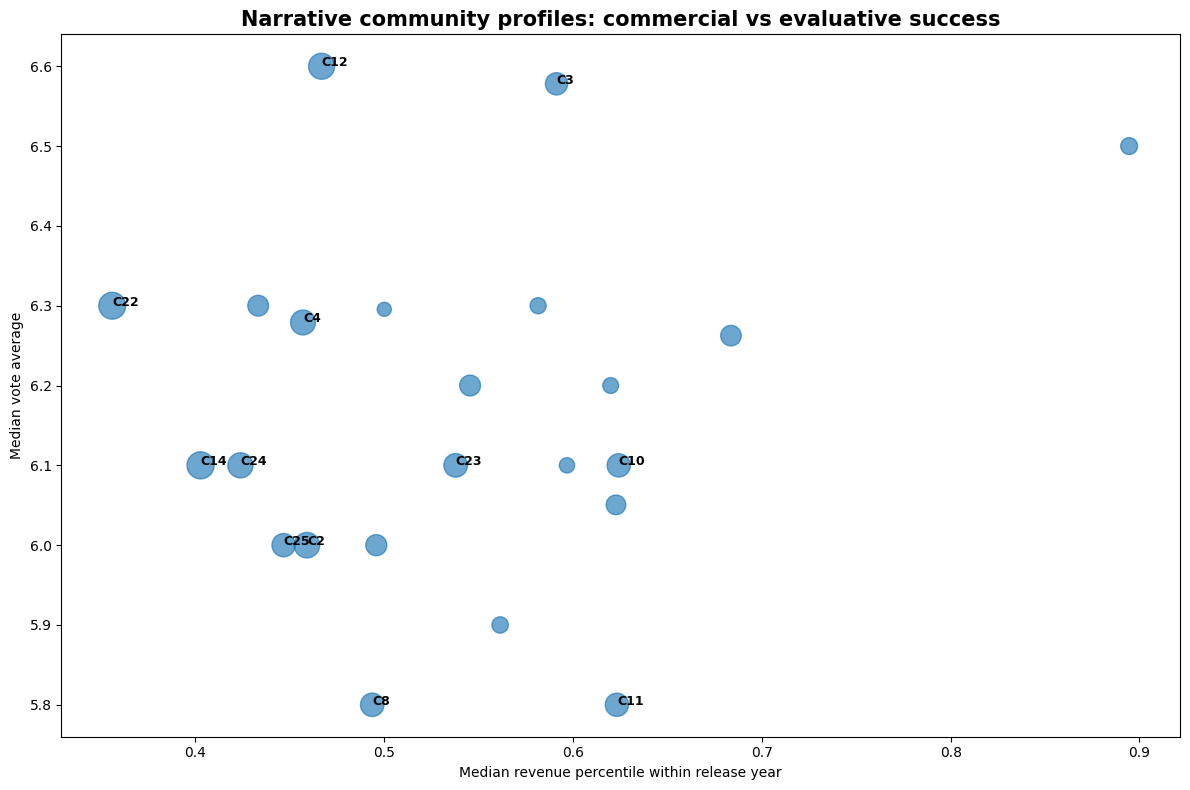

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/18_community_revenue_vs_rating_profile_data.csv


In [27]:
if community_success is not None and not community_success.empty:
    cs = community_success.copy()
    if "narrative_label" not in cs.columns:
        cs = cs.merge(label_lookup, on="community_id", how="left")

    if all(c in cs.columns for c in ["median_revenue_percentile_year", "median_vote_average", "n_films"]):
        cs_plot = cs.dropna(subset=["median_revenue_percentile_year", "median_vote_average"]).copy()
        cs_plot = cs_plot.sort_values("n_films", ascending=False).head(23)

        plt.figure(figsize=(12, 8))
        plt.scatter(
            cs_plot["median_revenue_percentile_year"],
            cs_plot["median_vote_average"],
            s=np.sqrt(cs_plot["n_films"]) * 9,
            alpha=0.65
        )

        for _, r in cs_plot.sort_values("n_films", ascending=False).head(12).iterrows():
            plt.text(
                r["median_revenue_percentile_year"],
                r["median_vote_average"],
                f"C{int(r['community_id'])}",
                fontsize=9,
                fontweight="bold"
            )

        plt.xlabel("Median revenue percentile within release year")
        plt.ylabel("Median vote average")
        plt.title("Narrative community profiles: commercial vs evaluative success", fontsize=15, fontweight="bold")
        plt.tight_layout()
        savefig("18_community_revenue_vs_rating_profile.png")
        plt.show()

        save_table(cs_plot, "18_community_revenue_vs_rating_profile_data.csv")
    else:
        print("Required columns not available.")
else:
    print("Community success not available.")

# PART G — Final organization outputs

This section creates an index so you know which files matter.


## Final visual index

In [28]:
visual_index = pd.DataFrame([
    {
        "figure_id": "Figure 1",
        "file": "01_pipeline_diagram.png",
        "chapter_use": "Methodology / Results opening",
        "message": "The thesis workflow converts plot text into a narrative network."
    },
    {
        "figure_id": "Figure 2",
        "file": "02_corpus_funnel.png",
        "chapter_use": "Data chapter",
        "message": "The analysis uses a curated pipeline from raw/curated films to final network and outcome subsets."
    },
    {
        "figure_id": "Figure 3",
        "file": "03_network_summary_dashboard.png",
        "chapter_use": "Results opening",
        "message": "The final network is large but interpretable."
    },
    {
        "figure_id": "Figure 4",
        "file": "04_network_map_community_sample.png",
        "chapter_use": "Main network result",
        "message": "Films can be visualized as a story-similarity network colored by narrative community."
    },
    {
        "figure_id": "Figure 5",
        "file": "05_major_communities_bar.png",
        "chapter_use": "Narrative communities",
        "message": "The graph contains major narrative neighborhoods with different sizes."
    },
    {
        "figure_id": "Figure 6",
        "file": "06_story_community_cards.png",
        "chapter_use": "Narrative communities",
        "message": "Community labels are translated into human-readable story cards."
    },
    {
        "figure_id": "Figure 7",
        "file": "08_central_vs_bridging_scatter.png",
        "chapter_use": "Central and bridging roles",
        "message": "Centrality metrics separate typical story examples from bridging positions."
    },
    {
        "figure_id": "Figure 8",
        "file": "11_success_dimensions_diagram.png",
        "chapter_use": "Success definition",
        "message": "Success is multidimensional, not only box office."
    },
    {
        "figure_id": "Figure 9",
        "file": "12_hidden_evaluative_success_quadrant.png",
        "chapter_use": "Success analysis",
        "message": "Some films show stronger evaluative success than commercial position."
    },
    {
        "figure_id": "Figure 10",
        "file": "13_fan_attention_success_quadrant.png",
        "chapter_use": "Success analysis",
        "message": "Some films show fan/attention success beyond revenue position."
    },
    {
        "figure_id": "Figure 11",
        "file": "14_community_success_heatmap.png",
        "chapter_use": "Community outcome profiles",
        "message": "Narrative communities differ across success dimensions."
    },
    {
        "figure_id": "Figure 12",
        "file": "15_model_fit_by_success_dimension.png",
        "chapter_use": "Model summary",
        "message": "Narrative-network models relate more clearly to ratings than to popularity."
    },
    {
        "figure_id": "Figure 13",
        "file": "16_model_improvement_gains.png",
        "chapter_use": "Model summary",
        "message": "Community effects and cast exposure add different explanatory value."
    },
    {
        "figure_id": "Figure 14",
        "file": "18_community_revenue_vs_rating_profile.png",
        "chapter_use": "Discussion",
        "message": "Narrative communities can be positioned by commercial and evaluative success profiles."
    },
])

save_table(visual_index, "final_visual_index.csv")
display(visual_index)

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_final/tables/final_visual_index.csv


,figure_id,file,chapter_use,message
0,Figure 1,01_pipeline_diagram.png,Methodology / Results opening,The thesis workflow converts plot text into a narrative network.
1,Figure 2,02_corpus_funnel.png,Data chapter,The analysis uses a curated pipeline from raw/curated films to final network and outcome subsets.
2,Figure 3,03_network_summary_dashboard.png,Results opening,The final network is large but interpretable.
3,Figure 4,04_network_map_community_sample.png,Main network result,Films can be visualized as a story-similarity network colored by narrative community.
4,Figure 5,05_major_communities_bar.png,Narrative communities,The graph contains major narrative neighborhoods with different sizes.
5,Figure 6,06_story_community_cards.png,Narrative communities,Community labels are translated into human-readable story cards.
6,Figure 7,08_central_vs_bridging_scatter.png,Central and bridging roles,Centrality metrics separate typical story examples from bridging positions.
7,Figure 8,11_success_dimensions_diagram.png,Success definition,"Success is multidimensional, not only box office."
8,Figure 9,12_hidden_evaluative_success_quadrant.png,Success analysis,Some films show stronger evaluative success than commercial position.
9,Figure 10,13_fan_attention_success_quadrant.png,Success analysis,Some films show fan/attention success beyond revenue position.


## Create final short text note

In [30]:
note = '''
VISUAL RESULTS GALLERY — HOW TO USE THESE FILES

This notebook creates a figure-first version of the thesis results.

The main thesis should not show every CSV table. Use the CSVs as technical backing.
The main text should use selected figures and only a few summary tables.

Recommended main-body figures:
1. 01_pipeline_diagram.png
2. 03_network_summary_dashboard.png
3. 04_network_map_community_sample.png
4. 05_major_communities_bar.png
5. 06_story_community_cards.png
6. 08_central_vs_bridging_scatter.png
7. 11_success_dimensions_diagram.png
8. 12_hidden_evaluative_success_quadrant.png
9. 14_community_success_heatmap.png
10. 15_model_fit_by_success_dimension.png

Recommended appendix figures:
- 02_corpus_funnel.png
- 07_community_genre_mix_heatmap.png
- 09_central_films_examples_board.png
- 10_bridging_films_examples_board.png
- 13_fan_attention_success_quadrant.png
- 16_model_improvement_gains.png
- 17_community_size_vs_vote_average.png
- 18_community_revenue_vs_rating_profile.png

Main message:
This thesis builds a plot-based semantic film network using NLP.
It reveals narrative communities and story roles, then compares these structures with multiple success signals.
'''.strip()

note_path = FINAL_TEXT_DIR / "visual_gallery_usage_note.txt"
note_path.write_text(note, encoding="utf-8")
print(note)
print("\nSaved:", note_path)

VISUAL RESULTS GALLERY — HOW TO USE THESE FILES

This notebook creates a figure-first version of the thesis results.

The main thesis should not show every CSV table. Use the CSVs as technical backing.
The main text should use selected figures and only a few summary tables.

Recommended main-body figures:
1. 01_pipeline_diagram.png
2. 03_network_summary_dashboard.png
3. 04_network_map_community_sample.png
4. 05_major_communities_bar.png
5. 06_story_community_cards.png
6. 08_central_vs_bridging_scatter.png
7. 11_success_dimensions_diagram.png
8. 12_hidden_evaluative_success_quadrant.png
9. 14_community_success_heatmap.png
10. 15_model_fit_by_success_dimension.png

Recommended appendix figures:
- 02_corpus_funnel.png
- 07_community_genre_mix_heatmap.png
- 09_central_films_examples_board.png
- 10_bridging_films_examples_board.png
- 13_fan_attention_success_quadrant.png
- 16_model_improvement_gains.png
- 17_community_size_vs_vote_average.png
- 18_community_revenue_vs_rating_profile.png

Ma

## Final output check

In [31]:
figure_files = sorted(FINAL_FIGURES_DIR.glob("*.png"))
table_files = sorted(FINAL_TABLES_DIR.glob("*.csv"))
text_files = sorted(FINAL_TEXT_DIR.glob("*.txt"))

print("Figures created:", len(figure_files))
for p in figure_files:
    print("-", p.name)

print("\nTables created:", len(table_files))
for p in table_files:
    print("-", p.name)

print("\nText files created:", len(text_files))
for p in text_files:
    print("-", p.name)

Figures created: 18
- 01_pipeline_diagram.png
- 02_corpus_funnel.png
- 03_network_summary_dashboard.png
- 04_network_map_community_sample.png
- 05_major_communities_bar.png
- 06_story_community_cards.png
- 07_community_genre_mix_heatmap.png
- 08_central_vs_bridging_scatter.png
- 09_central_films_examples_board.png
- 10_bridging_films_examples_board.png
- 11_success_dimensions_diagram.png
- 12_hidden_evaluative_success_quadrant.png
- 13_fan_attention_success_quadrant.png
- 14_community_success_heatmap.png
- 15_model_fit_by_success_dimension.png
- 16_model_improvement_gains.png
- 17_community_size_vs_vote_average.png
- 18_community_revenue_vs_rating_profile.png

Tables created: 14
- 01_corpus_funnel_counts.csv
- 04_network_map_metadata.csv
- 05_major_communities_for_plot.csv
- 07_community_genre_mix_long.csv
- 09_central_films_examples_board_data.csv
- 10_bridging_films_examples_board_data.csv
- 12_hidden_evaluative_success_candidates.csv
- 13_fan_attention_success_candidates.csv
- 14_co

## What comes next

After this notebook, your thesis folder should feel much less chaotic.

Use:

```text
outputs/thesis_final/figures/
outputs/thesis_final/tables/
outputs/thesis_final/text/
```

as the clean final folder.

Everything else is technical backup.
